# Olist Brazilian E-Commerce — Notebook 2: Exploratory Data Analysis

**Dataset:** Olist Brazilian E-Commerce Public Dataset (Kaggle) · 96,469 delivered orders ·
81,005 unique customers · September 2016 – August 2018

**Tools:** Python · pandas · Matplotlib · Seaborn · Plotly

> **Prerequisite:** this notebook assumes `01_data_cleaning.ipynb` has already been run
> and has exported the clean CSVs. All data profiling, cleaning decisions and join
> validation live in that notebook — nothing is re-cleaned here.

---

## How to read this notebook

Every analysis follows the same four-step pattern, so the notebook can be read top to
bottom as a business report without reading a single line of code:

1. **Question** — the business question, in plain language
2. **Chart** — the visual that answers it
3. **Supporting numbers** — the exact figures behind the chart
4. **Finding** — what it means, and what the business should do about it

## Contents

| Section | The question it answers |
|---|---|
| **1 · Revenue & time patterns** | How is the business performing, and when do customers buy? |
| **2 · Products** | What are we selling, and which categories drive revenue? |
| **3 · Customers** | Who buys, do they come back, and what is a customer worth? |
| **4 · Geography** | Where do orders come from, and how does delivery differ by region? |
| **5 · RFM segmentation** | Which customers are most valuable, and which are slipping away? |
| **6 · Reviews** | How satisfied are customers, and what actually drives satisfaction? |

A consolidated **Key Findings Summary** closes the notebook.

## Setup

Imports and the global plotting style, matched to notebook 1 so both notebooks produce
visually consistent charts.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['figure.figsize'] = (12,5)


## 0 · Loading the cleaned data

Three files produced by notebook 1:

- **`master_orders`** — one row per delivered order (96,469), with revenue, customer,
  review score, payment and delivery features already joined on.
- **`master_products`** — one row per order item (112,650), carrying the English product
  category and the purchase date features.
- **`reviews_text`** — the 36,848 reviews that contain usable comment text.

The date columns are parsed on read, so the time-based analysis works immediately.

In [ ]:
master_orders = pd.read_csv('/content/master_orders.csv',
                            parse_dates=['order_purchase_timestamp',
                                         'order_delivered_customer_date',
                                         'order_estimated_delivery_date',
                                         'order_approved_at',
                                         'order_delivered_carrier_date'])
master_products = pd.read_csv('/content/master_products.csv')
reviews_text = pd.read_csv('/content/reviews_text_clean.csv')

print(f"master_orders: {master_orders.shape}")
print(f"master_products: {master_products.shape}")
print(f"reviews_text: {reviews_text.shape}")

master_orders: (96469, 24)
master_products: (112650, 13)
reviews_text: (36848, 7)


### What this notebook sets out to answer

This notebook performs the EDA on the cleaned Olist sales data, working through six
business questions in the order a stakeholder would naturally ask them:

- **Revenue analysis** — how is the business performing over time? The first question any
  stakeholder asks.
- **Product analysis** — what are we selling? Which categories drive revenue?
- **Customer behaviour** — who is buying? New vs returning, order patterns.
- **Geographic analysis** — where are orders coming from? Regional patterns.
- **RFM segmentation** — the centrepiece of the project. Segments customers by value.
- **Review analysis** — how satisfied are customers? Connects back to the RFM segments.

## Scoping the analysis window

Two boundary issues were identified in the raw monthly data:

**Start (Sep–Dec 2016)** — platform launch/pilot phase. Order volume ranged from 1 to 265
per month against 700+ from 2017-01 onward. These months produce meaningless growth
percentages (one month showed >600,000% MoM growth off a near-zero base) and do not
represent real business activity.

**End (Aug 2018)** — data collection ends 2018-08-29, making August an incomplete month
with roughly 3 fewer days than a full month, which partly explains the apparent revenue
decline.

**Decision:** time-based analysis is filtered to **2017-01 through 2018-07** — Olist's
stable, fully-recorded operating period.

Two dataframes are therefore carried through the notebook, and every section states which
one it uses and why:

| Dataframe | Scope | Used for |
|---|---|---|
| `master_orders_full` | all 96,469 delivered orders | geography, reviews — where coverage matters more than comparability |
| `master_orders_stable` | Jan 2017 – Jul 2018 | time series, cohorts, RFM — where month-on-month comparability matters |

In [ ]:
# Full dataset for context, geography, reviews
master_orders_full = master_orders.copy()

# Stable period- for time series, RFM analysis, customer
master_orders_stable = master_orders[
    (master_orders['order_purchase_timestamp'] >= '2017-01') &
    (master_orders['order_purchase_timestamp'] <= '2018-07')
].copy()

print(f"Full dataset: {len(master_orders_full):,} orders")
print(f"Stable period: {len(master_orders_stable):,} orders")
print(f"Excluded (soft-launch + incomplete final month): "
      f"{len(master_orders_full) - len(master_orders_stable):,} orders")


Full dataset: 96,469 orders
Stable period: 83,695 orders
Excluded (soft-launch + incomplete final month): 12,774 orders


---

# Section 1 · Revenue & time patterns

*Trend analysis uses `master_orders_stable`; the day/hour heatmap uses
`master_orders_full`, where every order adds signal regardless of month.*

## Q1 — What is the monthly revenue trend?

Monthly revenue with a 3-month rolling average, which separates the underlying trend from
month-to-month noise, and an annotated peak so the headline number is readable without
checking the axis.

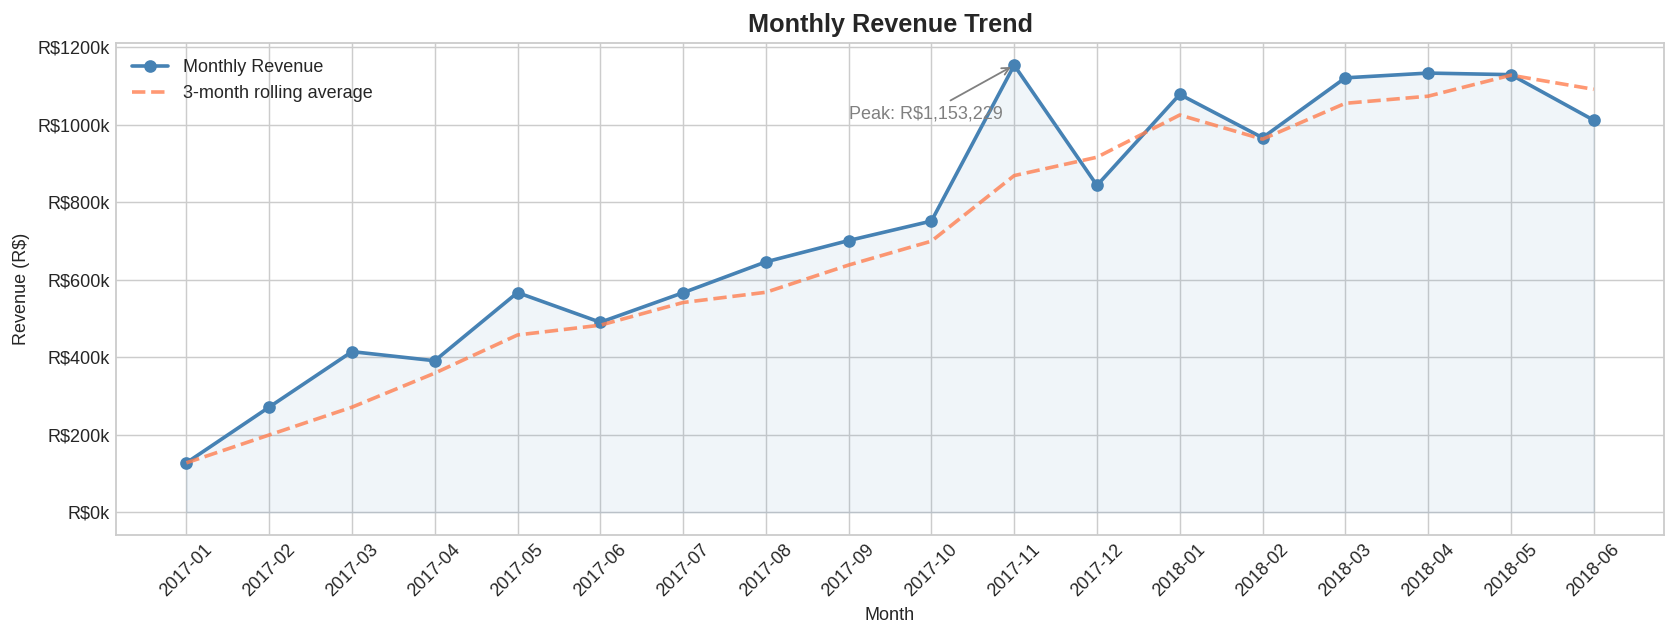

Total revenue: R$13,358,769
Peak month: 2017-11 — R$1,153,229
Average monthly revenue: 742,154


In [ ]:
# monthly revenue + rolling average
monthly_full = (master_orders_stable
           .groupby('purchase_month')
           .agg(revenue = ('total_revenue','sum'),
                orders = ('order_id','count'),
                aov = ('total_revenue','mean'))
           .reset_index())



monthly_full['rolling_avg'] = monthly_full['revenue'].rolling(3, min_periods=1).mean()
monthly_full['mom_growth'] = monthly_full['revenue'].pct_change() * 100

fig, ax = plt.subplots(figsize=(13,5))
ax.plot(monthly_full['purchase_month'], monthly_full['revenue'],
        marker = 'o', linewidth = 2, color = 'steelblue', label = 'Monthly Revenue')
ax.plot(monthly_full['purchase_month'], monthly_full['rolling_avg'],
        linewidth = 2, linestyle = '--', color = 'coral', alpha = 0.8, label = '3-month rolling average')
ax.fill_between(range(len(monthly_full)), monthly_full['revenue'], alpha = 0.08, color = 'steelblue')

# Annotate peak
peak = monthly_full.loc[monthly_full['revenue'].idxmax()]
peak_pos = monthly_full.index.get_loc(peak.name)
ax.annotate(f"Peak: R${peak['revenue']:,.0f}",
            xy = (peak_pos, peak['revenue']),
            xytext= (peak_pos-2, peak['revenue']*0.88),
            arrowprops= dict(arrowstyle = '->', color='gray'),
            fontsize = 10, color='gray')

ax.set_title('Monthly Revenue Trend', fontsize = 14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (R$)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'R${x/1000:.0f}k'))
ax.tick_params(axis='x', rotation = 45)
ax.legend()
plt.tight_layout()
# plt.savefig('/content/charts/monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total revenue: R${monthly_full['revenue'].sum():,.0f}")
print(f"Peak month: {peak['purchase_month']} — R${peak['revenue']:,.0f}")
print(f"Average monthly revenue: {monthly_full['revenue'].mean():,.0f}")

### Q2 — Which months grew, and which declined?

The line chart shows the level; this shows the change. Green bars are growth months, red
bars declines — the pattern is readable without a legend.

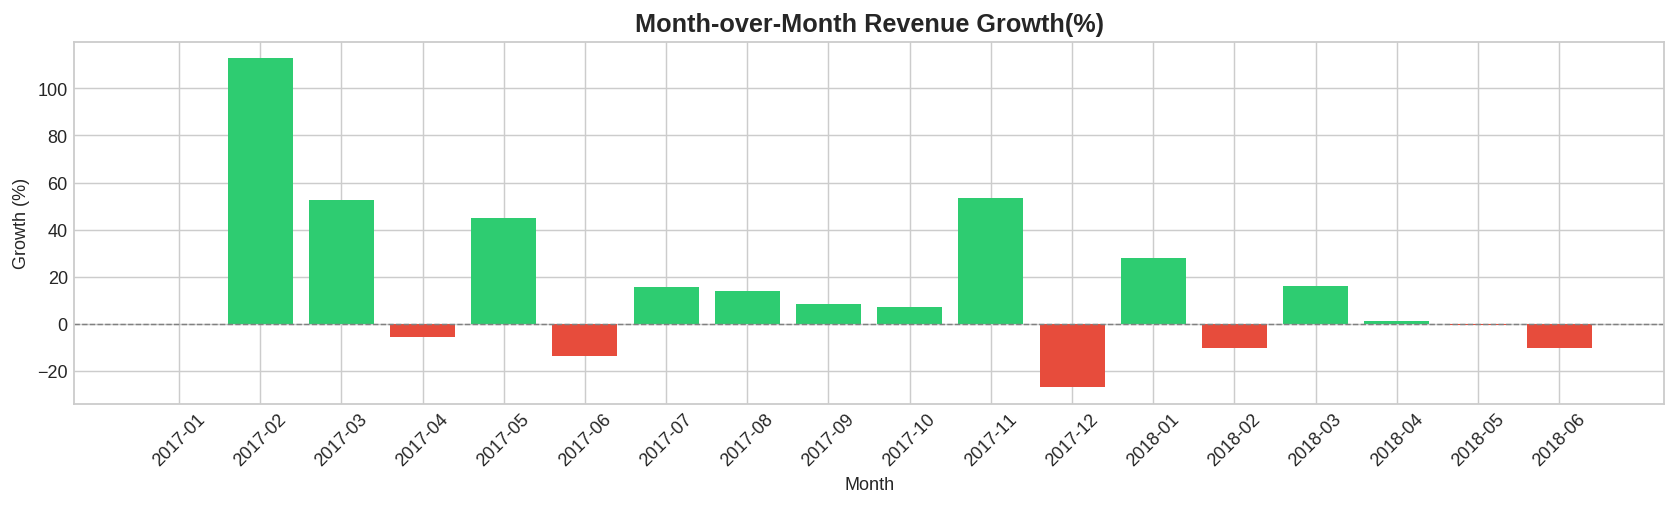

In [ ]:
# MOM Growth
fig, ax = plt.subplots(figsize=(13,4))
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in monthly_full['mom_growth'].fillna(0)]
ax.bar(monthly_full['purchase_month'], monthly_full['mom_growth'].fillna(0), color = colors)
ax.axhline(0, color='gray', linestyle = '--', linewidth = 0.8)
ax.set_title('Month-over-Month Revenue Growth(%)', fontsize = 14, fontweight= 'bold')
ax.set_xlabel('Month')
ax.set_ylabel('Growth (%)')
ax.tick_params(axis='x', rotation = 45)
plt.tight_layout()
plt.show()

The exact peak and trough figures behind both charts.

In [ ]:
# Find the peak month and its growth rate
peak_row = monthly_full.loc[monthly_full['revenue'].idxmax()]
print(f"Peak month: {peak_row['purchase_month']}")
print(f"Peak revenue: R${peak_row['revenue']:,.0f}")
print(f"MoM growth that month: {peak_row['mom_growth']:.1f}%")

# Find the biggest drop
trough_growth_row = monthly_full.loc[monthly_full['mom_growth'].idxmin()]
print(f"Biggest MoM decline: {trough_growth_row['purchase_month']}")
print(f"Decline: {trough_growth_row['mom_growth']:.1f}%")

Peak month: 2017-11
Peak revenue: R$1,153,229
MoM growth that month: 53.5%
Biggest MoM decline: 2017-12
Decline: -26.9%


## Finding — Monthly Revenue Trend

Revenue peaked in November 2017 at R\$1.15M — a 53.5% spike vs the prior month, likely
driven by Black Friday. December 2017 saw a ~27% drop, a typical post-holiday correction.
The underlying trend is upward.

## Q3 — When during the week do customers order?

A day × hour heatmap of order counts. This one uses `master_orders_full`: the question is
about behavioural rhythm rather than revenue growth, so every order counts and the
soft-launch months add signal instead of distortion.

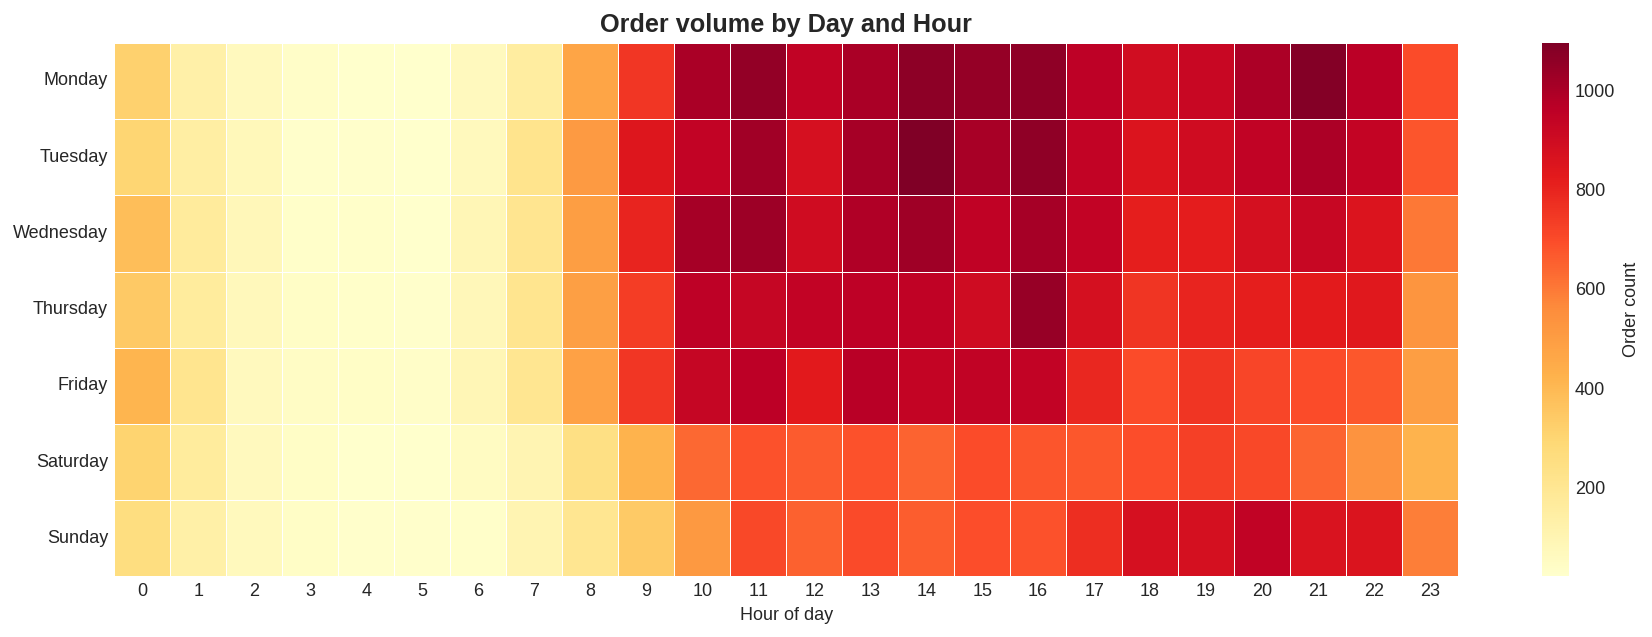

In [ ]:
# Day/Hour Heatmap
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = (master_orders_full
                .groupby(['purchase_day','purchase_hour'])['order_id']
                .count()
                .unstack(fill_value=0)
                .reindex(day_order))

fig, ax = plt.subplots(figsize= (14,5))
sns.heatmap(heatmap_data, cmap='YlOrRd', ax=ax, fmt='d',
            linewidths=0.3, cbar_kws={'label':'Order count'})
ax.set_title("Order volume by Day and Hour", fontweight = 'bold', fontsize = 14)
ax.set_xlabel('Hour of day')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

The heatmap shows the shape; the next four cells extract the exact numbers behind it —
starting with total orders in each hour of the day.

In [ ]:
# Finding the hourly range where actual activity starts
hourly_totals = heatmap_data.sum().reset_index()
hourly_totals.columns = ['hour','total_orders']
print(hourly_totals.to_string(index=False))

 hour  total_orders
    0          2321
    1          1133
    2           496
    3           259
    4           203
    5           182
    6           477
    7          1199
    8          2906
    9          4647
   10          5978
   11          6385
   12          5802
   13          6309
   14          6383
   15          6249
   16          6475
   17          5961
   18          5585
   19          5801
   20          6007
   21          6039
   22          5658
   23          4014


Rather than eyeballing "the busy period", the active window is defined quantitatively:
every hour at or above the 75th percentile of hourly volume.

In [ ]:
threshold = hourly_totals['total_orders'].quantile(0.75)
peak_hours = hourly_totals[hourly_totals['total_orders'] >= threshold]
print(f"75th percentile threshold: {threshold:,.0f} orders")
print(f"Peak window: {int(peak_hours['hour'].min())}:00 - {int(peak_hours['hour'].max())}:00")

busiest_hour = hourly_totals.loc[hourly_totals['total_orders'].idxmax()]
print(f"\nSingle busiest hour: {int(busiest_hour['hour'])}:00 "
      f"with {busiest_hour['total_orders']:,} orders")

75th percentile threshold: 6,015 orders
Peak window: 11:00 - 21:00

Single busiest hour: 16:00 with 6,475 orders


Quantifying the overnight trough against daytime volume.

In [ ]:
# Quantify the overnight drop
overnight = hourly_totals[hourly_totals['hour'].between(0,7)]['total_orders'].sum()
daytime = hourly_totals[hourly_totals['hour'].between(8,23)]['total_orders'].sum()
print(f"Overnight volume: {overnight:,} orders ({overnight/(overnight+daytime)*100:.1f}% of day + overnight)")
print(f"Daytime volume: {daytime:,} orders ({daytime/(daytime+overnight)*100:.1f})")

Overnight volume: 6,270 orders (6.5% of day + overnight)
Daytime volume: 90,199 orders (93.5)


The midnight bar looks anomalous. If it were genuine behaviour it would concentrate on
particular days; if it is a timezone artefact it will be spread evenly across all seven.
This checks which.

In [ ]:
# Check if midnight spike is consistent across all days or specific ones
midnight_by_day = master_orders_stable[
    master_orders_stable['purchase_hour'] == 0
].groupby('purchase_day')['order_id'].count()
print(midnight_by_day)

purchase_day
Friday       366
Monday       271
Saturday     279
Sunday       224
Thursday     298
Tuesday      266
Wednesday    335
Name: order_id, dtype: int64


Peak day/hour slot, weekday vs weekend split, and the dead-hours share — the last of the
supporting numbers.

In [ ]:
# Find the actual peak day/hour combination
peak_cell = heatmap_data.stack().idxmax()
peak_count = heatmap_data.stack().max()
print(f"Peak Slot: {peak_cell[0]} at {peak_cell[1]} hour - {peak_count:,} orders")

# Compare weekdays vs weekend totals
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekend = ['Saturday', 'Sunday']
weekdays_total = heatmap_data.loc[weekdays].sum().sum()
weekend_total = heatmap_data.loc[weekend].sum().sum()
print(f"Weekday orders: {weekdays_total:,}")
print(f"Weekend orders: {weekend_total:,}")
print(f"Weekend is {weekend_total/weekdays_total*100:.1f}% of weekday volume")

# Find the peak hour across all days
peak_hour = heatmap_data.sum().idxmax()
print(f"Peak hour overall: {peak_hour}:00")

# Find dead hours (before business picks up)
dead_hours = heatmap_data.loc[:, 0:6].sum().sum()
active_hours = heatmap_data.loc[:, 7:23].sum().sum()
print(f"Orders placed 0-6am: {dead_hours:,} ({dead_hours/(dead_hours+active_hours)*100:.1f})%")

Peak Slot: Tuesday at 14 hour - 1,095 orders
Weekday orders: 74,282
Weekend orders: 22,187
Weekend is 29.9% of weekday volume
Peak hour overall: 16:00
Orders placed 0-6am: 5,071 (5.3)%


## Finding — Order Volume by Day and Hour

Olist shows a broad, sustained 10-hour active window from 11:00 to 21:00,
rather than the single lunch-hour spike typical of many e-commerce platforms.
16:00 is technically the busiest single slot at 6,475 orders, but the entire
11am–9pm window consistently stays above the 75th percentile threshold of
6,015 orders — meaning volume is remarkably flat across this stretch.
This suggests Olist's customers browse and order throughout their working
afternoon and evening, not just at a single predictable moment.

The overnight period (midnight to 7am) accounts for just 6.5% of daily
volume (6,270 orders), bottoming out at 4–5am before recovering sharply
from 8am onward.

One anomaly worth noting: hour 0 (midnight) records a disproportionately
high 2,321 orders — far above surrounding hours like 1am (1,133) and 2am
(496). However, this spike is evenly distributed across all 7 days of the
week (224–366 orders per day), which rules out any single-day behavioural
pattern. The most likely explanation is a UTC timezone offset in the
timestamp recording — Brazil operates at UTC-3, meaning some orders
recorded at midnight UTC were actually placed at 9pm local time, which
falls squarely within the peak active window.

Business recommendation: the broad 11am–9pm active window gives marketing
campaigns significant scheduling flexibility — there is no single "magic
hour" to concentrate on. Instead, the real opportunity lies in the morning
recovery window: a push notification or email campaign deployed between
8–9am could capture customers at the start of their day, just as order
volume begins its sharp daily ramp-up, before the competition for attention
peaks later in the afternoon.

---

# Section 2 · Products

*Uses `master_products_stable` — the item-level table filtered to the same
Jan 2017 – Jul 2018 window as the revenue analysis, so category trends are directly
comparable with the charts above. The cell below applies that filter.*

In [ ]:
master_products_stable = master_products[
    (master_products['purchase_month'] >= '2017-01') &
    (master_products['purchase_month'] <= '2018-07')
].copy()

## Q4 — Which product categories drive the most revenue?

Total revenue alone ranks categories but does not explain them, so four derived metrics
are added on top:

- **`items_per_order`** — do customers buy more than one item from this category at a
  time? (bundling behaviour)
- **`order_penetration_pct`** — what share of all orders contain this category? (reach)
- **`avg_order_revenue`** — revenue per order containing the category (ticket size)
- **`avg_price`** — average item price; the gap between this and `avg_order_revenue`
  exposes embedded freight cost

Together these separate the high-reach everyday categories from the low-frequency premium
ones — a distinction that total revenue on its own hides completely.

In [ ]:
# Top categories + scatter
cat_stats = (master_products_stable
             .groupby('category_english')
             .agg(revenue = ('price','sum'),
                  orders = ('order_id','nunique'),
                  items_sold = ('order_item_id','count'),
                  avg_price = ('price','mean')
                  )
             .reset_index()
             .sort_values('revenue', ascending = False))

# Derived metric — items per order for each category
# High value = customers often buy multiple items from this category in one order
cat_stats['items_per_order'] = cat_stats['items_sold']/cat_stats['orders']

# Add a metric -- what % of all orders contained this category
total_unique_orders = master_products_stable['order_id'].nunique()
cat_stats['order_penetration_pct'] = (cat_stats['orders']/total_unique_orders * 100).round(2)

# Average revenue per order by category -- reveals the premium categories
cat_stats['avg_order_revenue'] = cat_stats['revenue'] / cat_stats['orders']

print(cat_stats.head(10)[
    ['category_english', 'revenue', 'orders', 'items_sold','items_per_order', 'order_penetration_pct', 'avg_order_revenue','avg_price']]
      .sort_values('avg_order_revenue', ascending=False).to_string(index=False))



     category_english    revenue  orders  items_sold  items_per_order  order_penetration_pct  avg_order_revenue  avg_price
        watches_gifts 1093420.85    5102        5442         1.066641                   5.68         214.312201 200.922611
           cool_stuff  593363.11    3436        3592         1.045402                   3.82         172.690079 165.190175
                 auto  532688.51    3456        3761         1.088252                   3.85         154.134407 141.634807
        health_beauty 1110166.49    7845        8587         1.094583                   8.73         141.512618 129.284557
computers_accessories  847891.96    6137        7216         1.175819                   6.83         138.160658 117.501657
         garden_tools  452820.70    3323        4127         1.241950                   3.70         136.268643 109.721517
       sports_leisure  901801.22    7080        7942         1.121751                   7.88         127.373054 113.548378
      furniture_

> **Note on order counting:** a single order can contain items from multiple categories.
> The `orders` metric counts how many distinct orders contained at least one item from each
> category — meaning one order can be counted across multiple categories simultaneously.
> This is intentional: it answers "how many customers bought from this category?" not "how
> many orders belonged exclusively to this category." Total order counts across categories
> will therefore exceed the actual order count in `master_orders`.

### Chart — top 15 categories by revenue

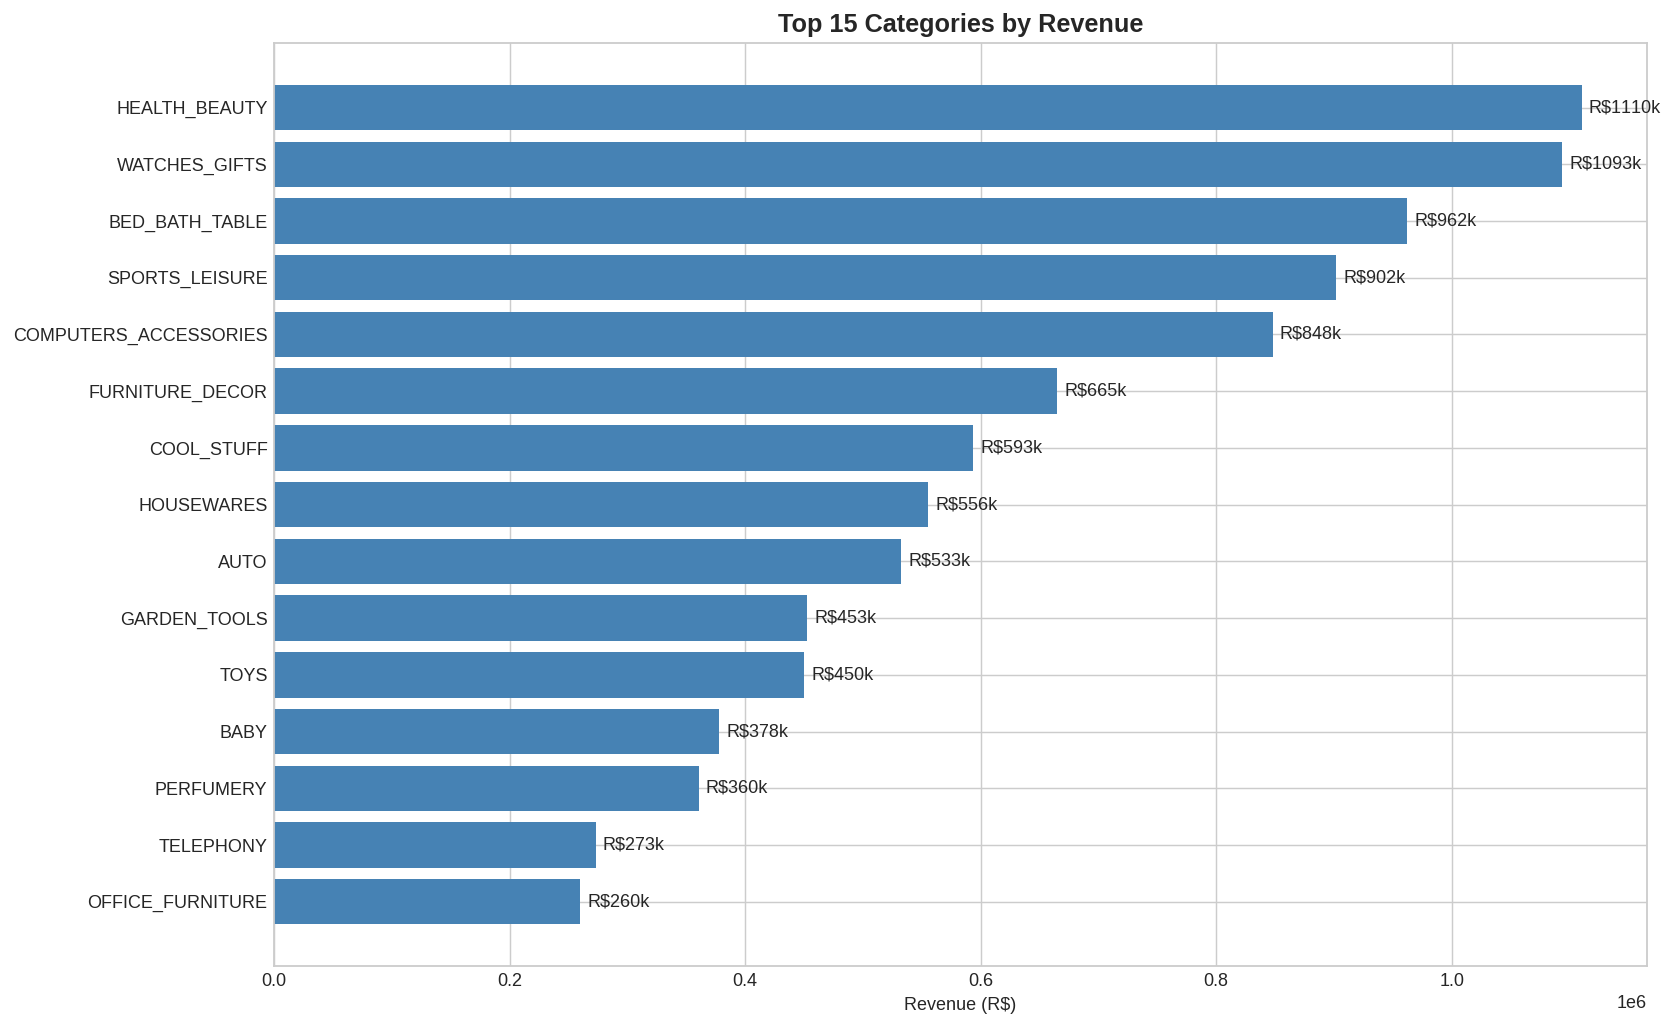

In [ ]:
top_15 = cat_stats.head(15).copy()

fig, ax = plt.subplots(figsize=(13,8))
bars = ax.barh(top_15['category_english'].str.upper(), top_15['revenue'], color='steelblue')
ax.bar_label(bars, labels=[f"R${v/1000:.0f}k" for v in top_15['revenue']], padding=4, fontsize=10)
ax.set_title("Top 15 Categories by Revenue", fontweight = 'bold', fontsize = 14)
ax.set_xlabel('Revenue (R$)')
ax.invert_yaxis()
plt.tight_layout()
# plt.savefig('../charts/top_categories_revenue.png', dpi=150, bbox_inches='tight')/*
plt.show()

### Chart — revenue vs reach, with ticket size as bubble area

Three variables in one view: orders on the x-axis (reach), revenue on the y-axis (scale),
and average order revenue as bubble size (ticket). The categories that sit large on one
axis and small on another are the interesting ones.

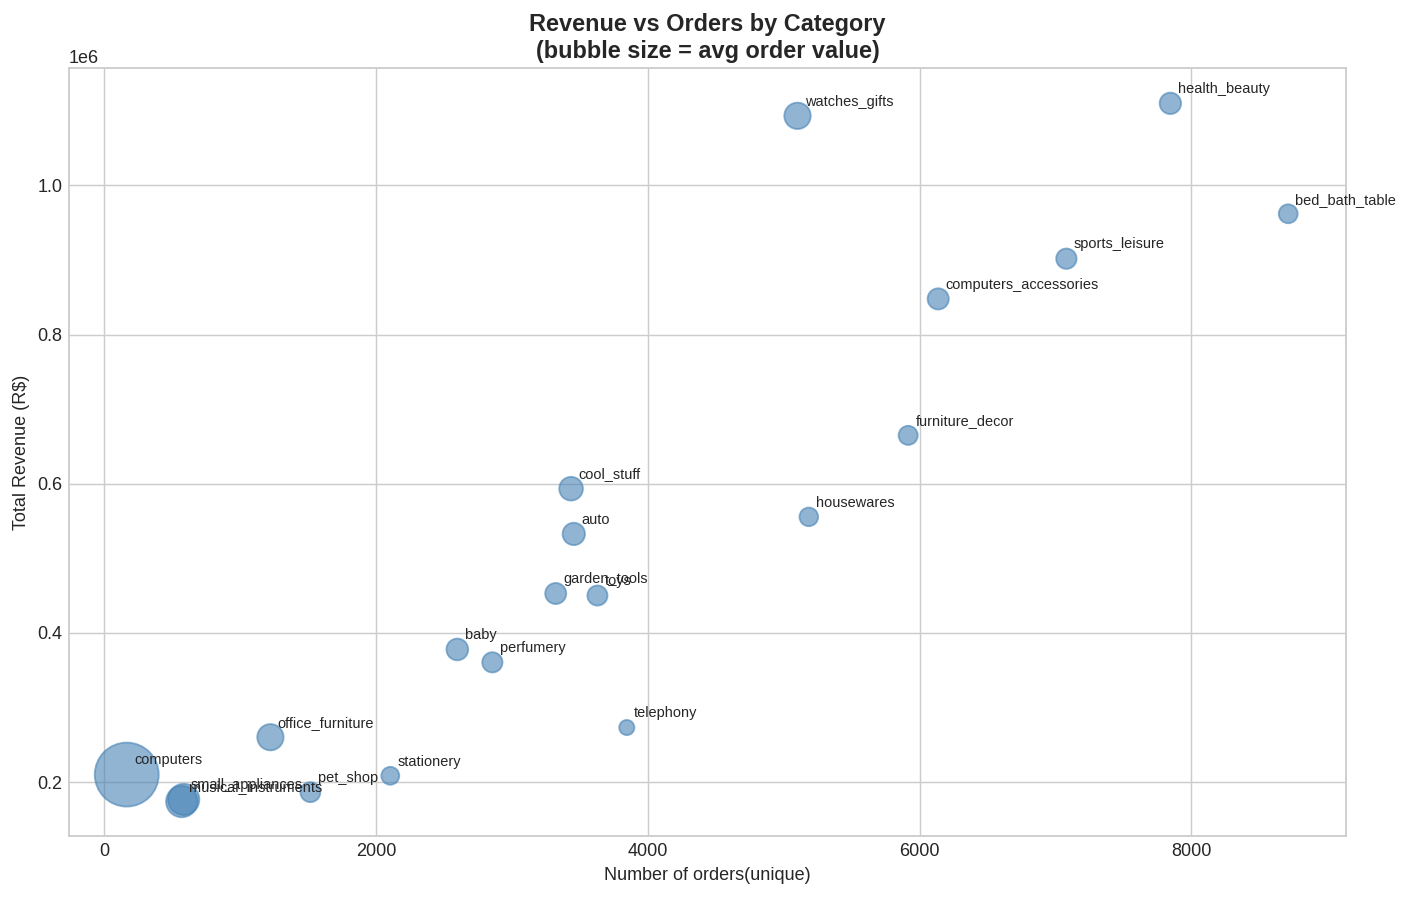

In [ ]:
# Scatter — revenue vs orders, bubble = avg_order_revenue
fig, ax= plt.subplots(figsize=(11,7))
ax.scatter(
    cat_stats.head(20)['orders'],
    cat_stats.head(20)['revenue'],
    s = cat_stats.head(20)['avg_order_revenue'],
    alpha = 0.6,
    color= 'steelblue'
)

# Label every point
for _, row in cat_stats.head(20).iterrows():
  ax.annotate(row['category_english'],
              (row['orders'],row['revenue']),
              fontsize = 8, ha = 'left', va = 'bottom',
              xytext=(4,4), textcoords='offset points')

ax.set_title("Revenue vs Orders by Category\n(bubble size = avg order value)", fontsize = 13, fontweight = 'bold')
ax.set_xlabel("Number of orders(unique)")
ax.set_ylabel("Total Revenue (R$)")
plt.tight_layout()
# plt.savefig('../charts/revenue_vs_orders.png', dpi=150, bbox_inches='tight')
plt.show()


## Finding — Product Category Analysis

### Revenue vs Reach
health_beauty leads total revenue at R$1,110,166 with the second-highest
order penetration (8.73%), making it the most commercially dominant
category — high reach AND high revenue. bed_bath_table has the highest
penetration of all (9.70%) but ranks 3rd by revenue, confirming it as
a high-frequency, lower-ticket everyday category.

### The Premium Outlier — watches_gifts
watches_gifts is the most strategically interesting category: ranked #2
by total revenue (R$1,093,420) but with only 5,102 orders and 5.68%
penetration — the lowest among the top 5. Its average order revenue of
R$214 is 94% higher than bed_bath_table (R$110), confirming a premium,
low-frequency purchase profile. These customers are rare but extremely
high-value when they do convert.

### Hidden Premium — cool_stuff
cool_stuff doesn't appear in the top 5 by volume or penetration (3.82%)
but ranks 2nd by average order revenue at R$172 — making it a high-value
niche hidden behind modest absolute numbers. Worth targeted premium
positioning despite its smaller customer base.

### Shipping cost signal
The gap between avg_order_revenue and avg_price reveals embedded freight
costs per category. furniture_decor shows the largest gap (R$112 vs R$86
= R$26 freight per order) — logical given bulky, heavy items. watches_gifts
shows almost no gap (R$214 vs R$200) — small, lightweight items where
freight is negligible relative to product value.

### Items per order
All categories sit between 1.04–1.24 items per order — customers
consistently buy one item per category per transaction with almost no
in-category bundling. This represents an untapped cross-sell opportunity:
if a customer is already buying a garden tool, they are almost never
buying a second garden tool in the same order.

### Business recommendations
- watches_gifts and cool_stuff warrant premium marketing with higher
  CAC tolerance — fewer customers but significantly higher revenue per
  conversion justify more expensive acquisition channels
- bed_bath_table and health_beauty suit volume retention strategies —
  broad reach and repeat potential make loyalty programmes and discounts
  economically viable here
- furniture_decor's high freight costs relative to item price may be
  suppressing conversion — a free shipping threshold test could
  meaningfully lift orders in this category

## Q5 — How have the top categories trended over time?

Whether a leading category got there through steady growth or through a single seasonal
spike changes what the business should do about it entirely.

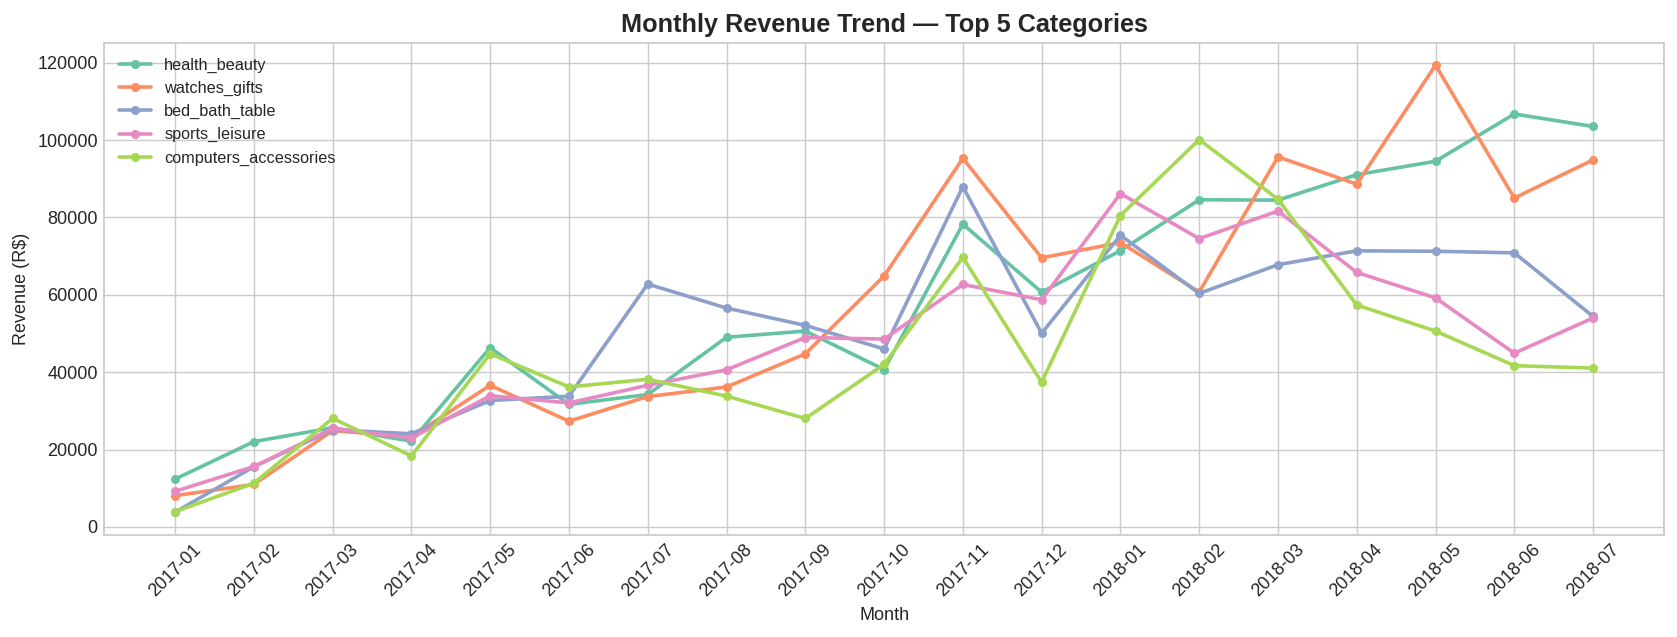

In [ ]:
# Category trend over time
top5_cats = cat_stats.head(5)['category_english'].tolist()

# Monthly revenue category - stable period only
cat_monthly = (master_products_stable
               .groupby(['purchase_month','category_english'])['price']
               .sum()
               .reset_index())
cat_monthly = cat_monthly[cat_monthly['category_english'].isin(top5_cats)]
cat_monthly['purchase_month'] = cat_monthly['purchase_month'].astype('str')
fig, ax = plt.subplots(figsize=(13, 5))
cmap = plt.get_cmap("Set2")
for i, cat in enumerate(top5_cats):
    data = cat_monthly[cat_monthly['category_english'] == cat]
    ax.plot(data['purchase_month'], data['price'],
            marker='o', linewidth=2, label=cat, markersize=4, color = cmap(i))


ax.set_title('Monthly Revenue Trend — Top 5 Categories',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (R$)')
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The same data as an animated race chart — identical story, in a format that presents
better in a stakeholder walkthrough than a static line chart.

In [ ]:
import plotly.express as px
fig = px.bar(
    cat_monthly,
    x='price',
    y='category_english',
    color='category_english',
    animation_frame='purchase_month',
    orientation='h',
    range_x=[0, cat_monthly['price'].max() * 1.1],
    title='Monthly Revenue by Category — Animated'
)

fig.update_layout(
    showlegend=False,
    xaxis_title='Revenue (R$)',
    yaxis_title='',
    yaxis={'categoryorder': 'total ascending'}
)
fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 700
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 700
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['easing'] = 'cubic-in-out'
fig.show()

Two specific claims from the chart, verified numerically rather than read off the line:
the November 2017 `watches_gifts` spike, and `health_beauty` growth across the full
period.

In [ ]:
# Confirm the November 2017 spike for watches_gifts
nov_watches = cat_monthly[
    (cat_monthly['purchase_month'] == '2017-11') &
    (cat_monthly['category_english'] == 'watches_gifts')
    ]['price'].values[0]

oct_watches = cat_monthly[
    (cat_monthly['purchase_month'] == '2017-10') &
    (cat_monthly['category_english'] == 'watches_gifts')
]['price'].values[0]

print(f"watches_gifts Oct 2017: R${oct_watches:,.0f}")
print(f"watches_gifts Nov 2017: R${nov_watches:,.0f}")
print(f"Spike: {(nov_watches-oct_watches)/oct_watches*100:.1f}%")

# Also check health_beauty growth from start to end
jan_hb = cat_monthly[
    (cat_monthly['category_english'] == 'health_beauty') &
    (cat_monthly['purchase_month'] == '2017-01')
]['price'].values[0]

jul_hb = cat_monthly[
    (cat_monthly['category_english'] == 'health_beauty') &
    (cat_monthly['purchase_month'] == '2018-07')
]['price'].values[0]

print(f"\nhealth_beauty Jan 2017: R${jan_hb:,.0f}")
print(f"health_beauty Jul 2018: R${jul_hb:,.0f}")
print(f"Growth over period: {(jul_hb-jan_hb)/jan_hb*100:.1f}%")

watches_gifts Oct 2017: R$64,875
watches_gifts Nov 2017: R$95,292
Spike: 46.9%

health_beauty Jan 2017: R$12,366
health_beauty Jul 2018: R$103,524
Growth over period: 737.1%


## Finding — Category Scatter & Trend Analysis

### Scatter — Four distinct category profiles emerge

health_beauty and bed_bath_table occupy the top-right quadrant —
high orders, high revenue, small bubbles — confirming them as
high-volume affordable categories with broad customer reach.

watches_gifts sits in the high-revenue, moderate-orders zone with
a medium bubble — a premium category that generates strong total
revenue from a smaller, higher-spending customer base.

computers is the most extreme outlier — the largest bubble on the
chart by far (highest avg order value) but positioned bottom-left
due to very low order volume. Customers rarely buy computers on
Olist, but when they do, the transaction value dwarfs every other
category.

cool_stuff and auto share a similar mid-chart position but with
notably larger bubbles than nearby categories like baby and
perfumery — hidden premium niches that pure revenue ranking would
overlook.

### Trend — Growth, stability, and seasonality tell different stories

health_beauty is the standout growth story — growing approximately
737.1% from January 2017 to July 2018, ending as the clear revenue
leader. Its consistent upward trajectory suggests genuine category
expansion, not just seasonal fluctuation.

watches_gifts is the most volatile category, dominated by a sharp
46.9% spike in November 2017 — almost certainly Black Friday gift
purchases — before reverting to baseline. Its revenue profile is
driven by a single seasonal event rather than steady demand.
This concentration creates risk: a weak Black Friday could
meaningfully impact annual revenue for this category.

bed_bath_table shows the flattest, most stable trend of all five —
predictable and consistent throughout the period with no major
spikes or drops. While this limits upside, it provides reliable
baseline revenue that planners can count on.

computers_accessories is the only category showing a slight
downward trajectory from mid-2018 — worth monitoring but not yet
conclusive given the data ends in July 2018.

### Business recommendations
- health_beauty warrants continued investment — organic growth
  trajectory is strong without apparent heavy discounting
- watches_gifts needs a Black Friday maximisation strategy —
  inventory, promotions, and logistics should be concentrated
  in October-November to capture the seasonal spike
- bed_bath_table's stability makes it ideal for subscription
  or replenishment-style promotions — customers are consistent
  and predictable

---

# Section 3 · Customers

*Uses `master_orders_stable`, aggregated on `customer_unique_id` — the column that
identifies a real person across orders. `customer_id` is regenerated for every order in
this dataset, so using it here would make every customer look like a one-time buyer.*

## Q6 — How many customers come back, and what is a repeat customer worth?

Customers are rolled up to one row each, labelled one-time or repeat, and then compared on
two dimensions that usually disagree: share of customers and share of revenue.

customer_type  customers  total_revenue    avg_ltv  avg_orders  customer_pct  revenue_pct
     One-time      78591    12616065.23 160.528117    1.000000     97.019937    94.440328
       Repeat       2414      742703.72 307.665170    2.114333      2.980063     5.559672


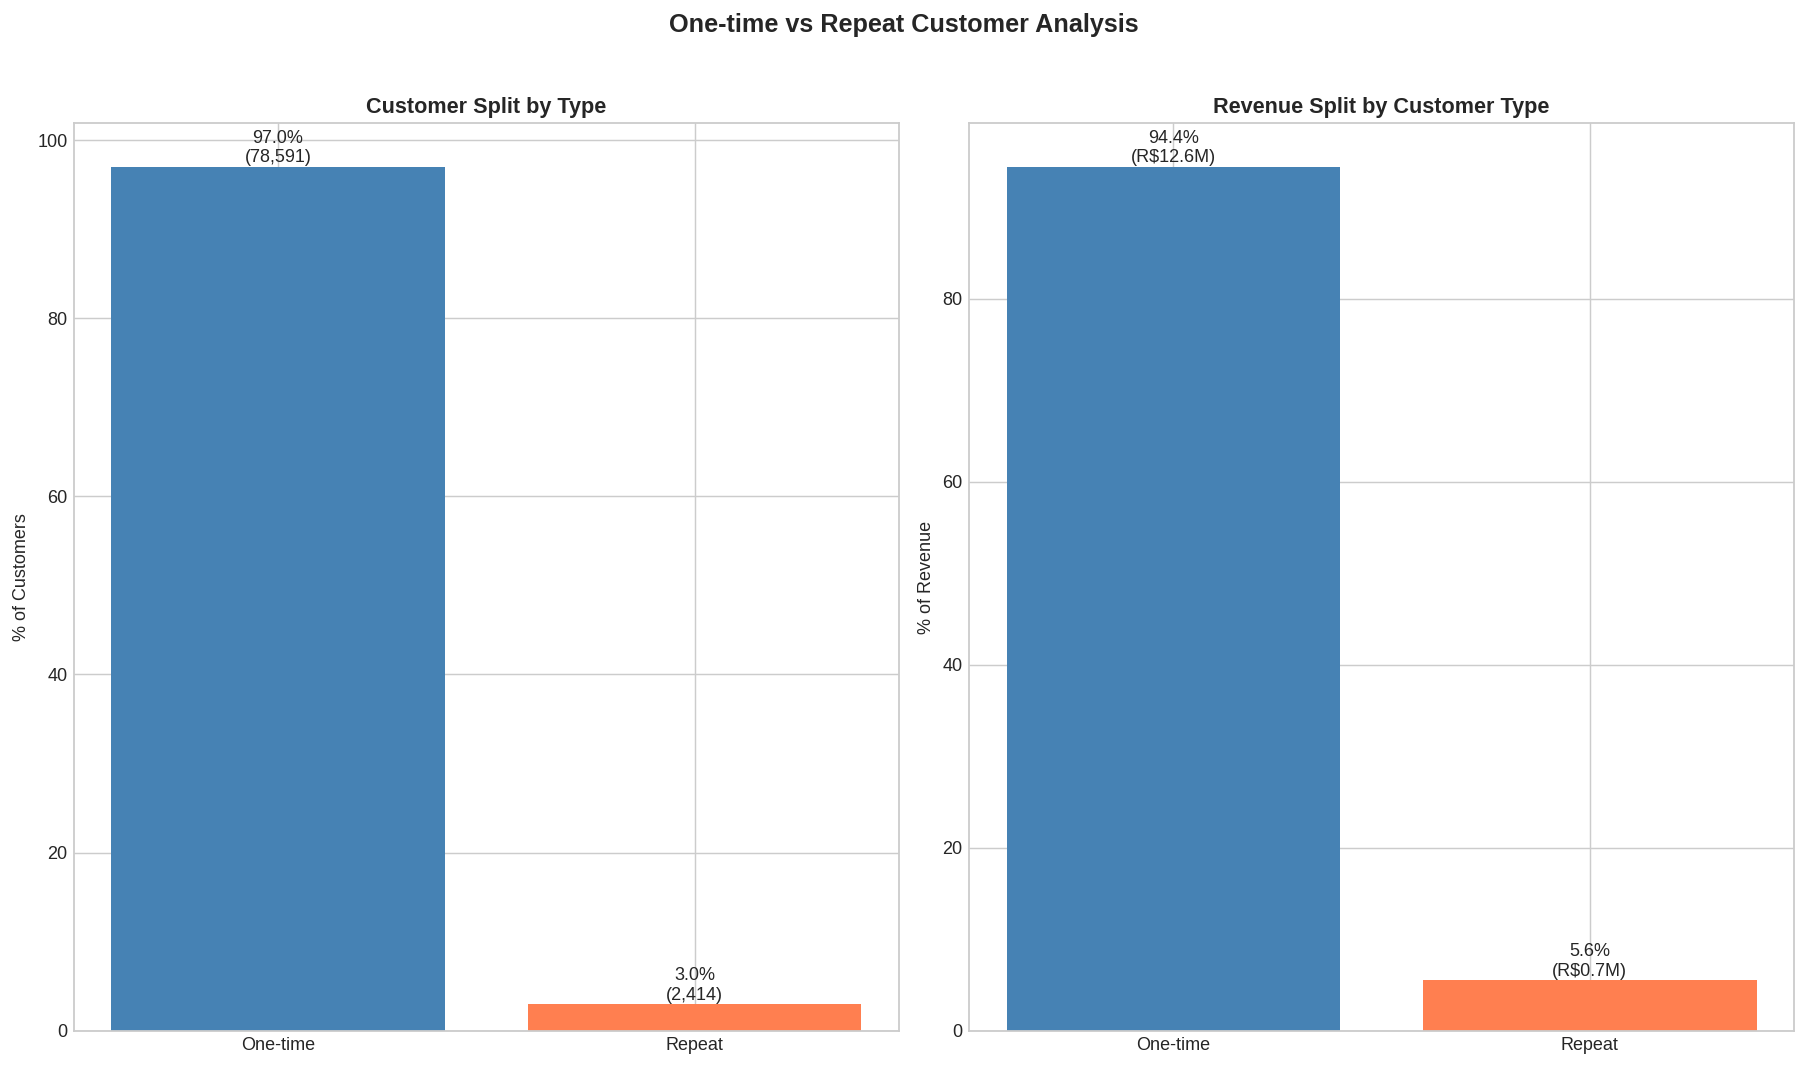

In [ ]:
customer_summary = (master_orders_stable
                    .groupby('customer_unique_id')
                    .agg(
                        order_count = ('order_id', 'count'),
                        total_spent = ('total_revenue', 'sum'),
                        first_order = ('order_purchase_timestamp', 'min'),
                        last_order = ('order_purchase_timestamp', 'max')
                    ).reset_index())

customer_summary['customer_type'] = customer_summary['order_count'].apply(
    lambda x: 'Repeat' if x > 1 else 'One-time'
)

type_stats = (customer_summary
              .groupby('customer_type')
              .agg(
                  customers = ('customer_unique_id', 'count'),
                  total_revenue = ('total_spent', 'sum'),
                  avg_ltv = ('total_spent', 'mean'),
                  avg_orders = ('order_count', 'mean')
              ).reset_index())

type_stats['customer_pct'] = type_stats['customers']/type_stats['customers'].sum() * 100
type_stats['revenue_pct'] = type_stats['total_revenue']/type_stats['total_revenue'].sum() * 100

print(type_stats.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14,8))

# Left - customer split
axes[0].bar(type_stats['customer_type'],
            type_stats['customer_pct'],
            color = ['steelblue','coral'])
axes[0].set_title('Customer Split by Type', fontweight = 'bold')
axes[0].set_ylabel('% of Customers')
for i, (pct, n) in enumerate(zip(type_stats['customer_pct'],type_stats['customers'])):
  axes[0].text(i, pct+0.5, f"{pct:.1f}%\n({n:,})", ha = 'center', fontsize = 10)

# Right - revenue split
axes[1].bar(type_stats['customer_type'],
            type_stats['revenue_pct'],
            color = ['steelblue', 'coral'])
axes[1].set_title('Revenue Split by Customer Type', fontweight = 'bold')
axes[1].set_ylabel('% of Revenue')
for i, (pct, rev) in enumerate(zip(type_stats['revenue_pct'], type_stats['total_revenue'])):
  axes[1].text(i, pct+0.5, f"{pct:.1f}%\n(R${rev/1e6:.1f}M)", ha = 'center', fontsize = 10)

plt.suptitle("One-time vs Repeat Customer Analysis", fontsize = 14, fontweight = 'bold', y = 1.02)
plt.tight_layout()
# plt.savefig('../charts/customer_type_split.png', dpi=150, bbox_inches='tight')
plt.show()


The headline split answers "how many". This answers "so what" — the lifetime value gap
between a one-time and a repeat customer.

In [ ]:
# Check avg_ltv gap between one-time and repeat
print(type_stats[['customer_type', 'avg_ltv', 'avg_orders']].to_string(index=False))

one_time_ltv = type_stats.loc[type_stats['customer_type'] == 'One-time', 'avg_ltv'].values[0]
repeat_ltv   = type_stats.loc[type_stats['customer_type'] == 'Repeat',   'avg_ltv'].values[0]
print(f"One-time avg LTV: R${one_time_ltv:.2f}")
print(f"Repeat avg LTV: R${repeat_ltv:.2f}")
print(f"Repeat customers are worth {repeat_ltv/one_time_ltv:.1f}x more per customer")

customer_type    avg_ltv  avg_orders
     One-time 160.528117    1.000000
       Repeat 307.665170    2.114333
One-time avg LTV: R$160.53
Repeat avg LTV: R$307.67
Repeat customers are worth 1.9x more per customer


Within repeat customers, is this a long tail of frequent buyers, or almost entirely
customers with exactly two orders?

In [ ]:
# What % of repeat customers have 3+ orders vs exactly 2?
repeat_only = customer_summary[customer_summary['customer_type'] == 'Repeat']
print(repeat_only['order_count'].value_counts().head(10))
print(f"\nAvg orders per repeat customer: {repeat_only['order_count'].mean():.2f}")

order_count
2     2216
3      157
4       23
5        9
6        4
7        3
9        1
10       1
Name: count, dtype: int64

Avg orders per repeat customer: 2.11


Sizing the opportunity: what a 1 percentage point improvement in the repeat rate would be
worth, using the LTV gap calculated above.

In [ ]:
# Number of one-time customers who would convert
new_repeats = 78591 * 0.01   # 1% of one-time customers = ~786 customers

# Extra revenue each converted customer generates
# (they go from spending one_time_ltv to repeat_ltv)
extra_revenue_per_customer = repeat_ltv - one_time_ltv

# Total incremental revenue
incremental_revenue = new_repeats * extra_revenue_per_customer

print(f"One-time customers: 78,591")
print(f"1% conversion:      {new_repeats:.0f} customers")
print(f"LTV gap:            R${extra_revenue_per_customer:.2f}")
print(f"Incremental revenue: R${incremental_revenue:,.0f}")

One-time customers: 78,591
1% conversion:      786 customers
LTV gap:            R$147.14
Incremental revenue: R$115,636


## Finding — One-time vs Repeat Customer Analysis

Olist's customer base is overwhelmingly one-time buyers: 97.0% of
customers (78,591) placed only a single order, accounting for 94.4%
(R$12.6M) of total revenue in the stable period.

Repeat customers represent just 3.0% of the base (2,414 customers)
and contribute 5.6% (R$0.7M) of revenue — a proportion roughly
matching their headcount share, suggesting no outsized revenue
concentration among loyalists in aggregate terms.

However, at the individual customer level the story is different.
The average repeat customer has placed avg 2.11 orders with a lifetime
value of R\$307 — approximately 1.9x higher than the average one-time
customer (R$160.5). This gap represents the true retention
opportunity: each customer converted from one-time to repeat is worth
1.9x more to the business over their lifetime.

The low repeat rate (3%) is actually typical for e-commerce
marketplaces — customers often visit Olist for a specific purchase
need rather than habitual shopping. However, even a modest improvement
in retention would have outsized revenue impact: converting just 1%
more one-time customers to repeat buyers would add approximately
R$115,636 in incremental
revenue.

Business recommendation: given the dominance of one-time buyers, the
highest-leverage retention intervention is the post-first-purchase
experience — specifically the window between delivery and 30 days
after. A targeted re-engagement campaign in this window (personalised
to the category purchased) could meaningfully move the 3% repeat rate,
with each percentage point gained worth approximately R$115,636 in
incremental annual revenue.

## Q7 — Is the customer base still growing?

New customers per month, dated by each customer's *first* order — so a customer is counted
once, in the month they were acquired, and never again. The 3-month rolling average
smooths the promotional spikes.

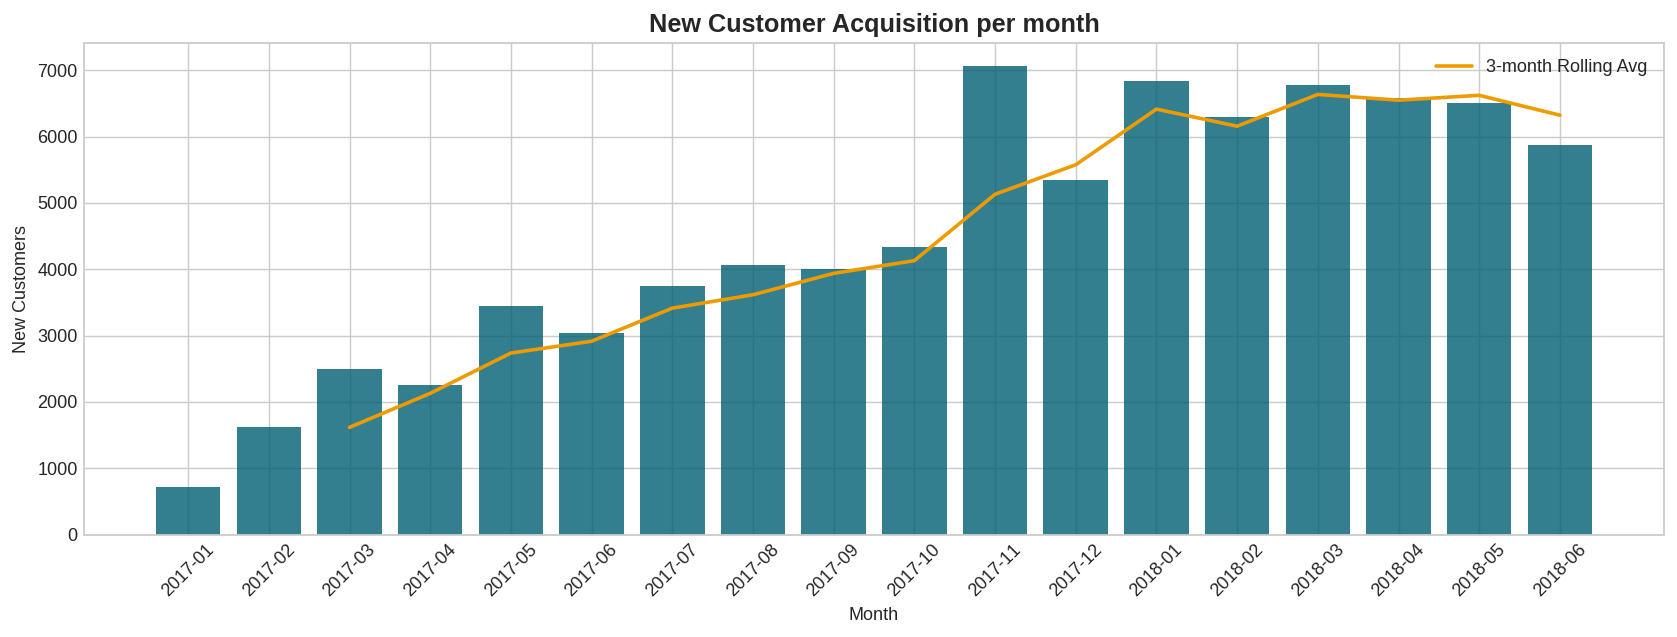

In [ ]:
from matplotlib.figure import figaspect
# New customer acquisition over time

# First order month per unique customer
first_orders = (master_orders_stable
                .groupby('customer_unique_id')['order_purchase_timestamp']
                .min()
                .reset_index())
first_orders.columns = ['customer_unique_id', 'first_order_date']
first_orders['acquisition_month'] = first_orders['first_order_date'].dt.to_period('M').astype(str)

new_customers_monthly = (first_orders
                         .groupby('acquisition_month')['customer_unique_id']
                         .count()
                         .reset_index())
new_customers_monthly.columns = ['month', 'new_customers']

fig, ax = plt.subplots(figsize= (13,5))
ax.bar(new_customers_monthly['month'],
       new_customers_monthly['new_customers'],
       color='#005F73', alpha = 0.8)
ax.plot(new_customers_monthly['month'],
        new_customers_monthly['new_customers'].rolling(3).mean(),
        color = '#EE9B00', linewidth = 2, label = '3-month Rolling Avg')
ax.set_title('New Customer Acquisition per month', fontweight = 'bold', fontsize = 14)
ax.set_xlabel('Month')
ax.set_ylabel('New Customers')
ax.tick_params(axis='x', rotation = 45)
ax.legend()
plt.tight_layout()
# plt.savefig('../charts/new_customer_acquisition.png', dpi=150, bbox_inches='tight')
plt.show()

Three checks on what the chart appears to show: the exact peak month, growth across the
full period, and whether the apparent plateau at the right-hand edge is real.

In [ ]:
# 1 — Confirm the November 2017 peak exactly
print(new_customers_monthly.sort_values('new_customers', ascending=False).head(3))

#2 — Calculate overall growth from first to last stable month
jan_2017 = new_customers_monthly[new_customers_monthly['month'] == '2017-01']['new_customers'].values[0]
jun_2018 = new_customers_monthly[new_customers_monthly['month'] == '2018-06']['new_customers'].values[0]
growth = (jun_2018 - jan_2017)/jan_2017 * 100
print(f"Growth Jan 2017 to June 2018: {growth:.1f}%")

# 3 — Check if plateau is real — average last 4 months vs middle 4 months
last_4 = new_customers_monthly.tail(4)['new_customers'].mean()
mid_4 = new_customers_monthly.iloc[8:12]['new_customers'].mean()
print(f"Mid-period avg (months 9-12): {mid_4:.0f}")
print(f"Recent avg (last 4 months): {last_4:.0f}")
print(f"Change: {(last_4 - mid_4)/mid_4 * 100:.1f}%")



      month  new_customers
10  2017-11           7060
12  2018-01           6843
14  2018-03           6775
Growth Jan 2017 to June 2018: 718.4%
Mid-period avg (months 9-12): 5182
Recent avg (last 4 months): 6435
Change: 24.2%


## Finding — New Customer Acquisition

Olist's new customer acquisition grew dramatically over the 18-month
stable period — from 750 new customers in January 2017 to 6,200 in
June 2018, a 718.4% increase. This is the clearest evidence that
Olist was a genuinely fast-growing marketplace during this period,
not a stagnant platform.

The standout month is November 2017 with 7,060 new customers —
the single highest acquisition month in the dataset, almost certainly
driven by Black Friday bringing first-time buyers onto the platform.
Critically, acquisition did not collapse after November — January 2018
(6,843) and March 2018 (6,775) both sustained near-peak levels,
suggesting the Black Friday cohort represented genuine new demand
rather than just a temporary promotional spike.

The recent 4-month average (6,435) is 24.2% higher than the
mid-period average (5,182), confirming that growth continued through
2018 but at a decelerating rate compared to the steep ramp-up of
2017. What appeared visually as a plateau is more precisely a
transition from explosive growth to steady-state growth — common
in marketplace businesses as they approach saturation in their
initial core markets.

Business recommendation: with acquisition growth decelerating
naturally, the highest-leverage next move is improving what happens
after a customer's first purchase. Specifically:

- Deploy a post-purchase email sequence triggered 7 days after
  delivery — personalised to the category purchased (a health_beauty
  buyer gets different content than a computers_accessories buyer)
  since category affinity is the strongest predictor of what a
  customer might buy next

- Prioritise the November 2017 Black Friday cohort for a re-engagement
  campaign — these 7,060 customers were acquired during a high-intent
  moment and represent the largest single-month acquisition in the
  dataset. Even a 5% reactivation rate would recover 353 customers
  at an expected repeat LTV of R\$307 each — approximately R$108,000
  in incremental revenue from a single targeted campaign

- As acquisition growth flattens toward a steady state of ~6,000–6,500
  new customers per month, begin gradually reallocating acquisition
  budget toward retention mechanics — loyalty points, personalised
  discounts at the 30-day post-purchase mark, and category-specific
  replenishment reminders — since each percentage point improvement
  in repeat rate adds approximately R$115,636 in annual revenue without acquiring a single
  new customer

However, whether retention investment is truly warranted depends on
a deeper question this chart cannot answer alone: are we actually
losing customers who wanted to come back, or are customers simply
satisfied with a single purchase and not in the market for more?
The cohort retention analysis below answers this directly — by
tracking what percentage of each monthly acquisition cohort returned
in subsequent months, we can determine whether low repeat rates
reflect a retention failure or simply the nature of the product
category.

## Q8 — Do customers come back, and is retention improving?

The repeat rate says how many customers ever returned. A cohort heatmap says *when* — and
whether customers acquired later behave differently from customers acquired earlier.

How the table is built:

- **`cohort_month`** — the month of each customer's first ever purchase. This is the cohort
  they belong to permanently.
- **`cohort_index`** — months elapsed between an order and that customer's cohort month.
  Index 0 is the acquisition month itself, so it is always 100%.
- Each cell is the percentage of that cohort still ordering that many months later.

Reading it: rows compare cohorts against each other, columns show decay over time, and
column 1 — Month-1 retention — is the single most diagnostic number in the table.

Max retention (any month after 0): 0.72%
Mean retention across all cohorts: 0.25%


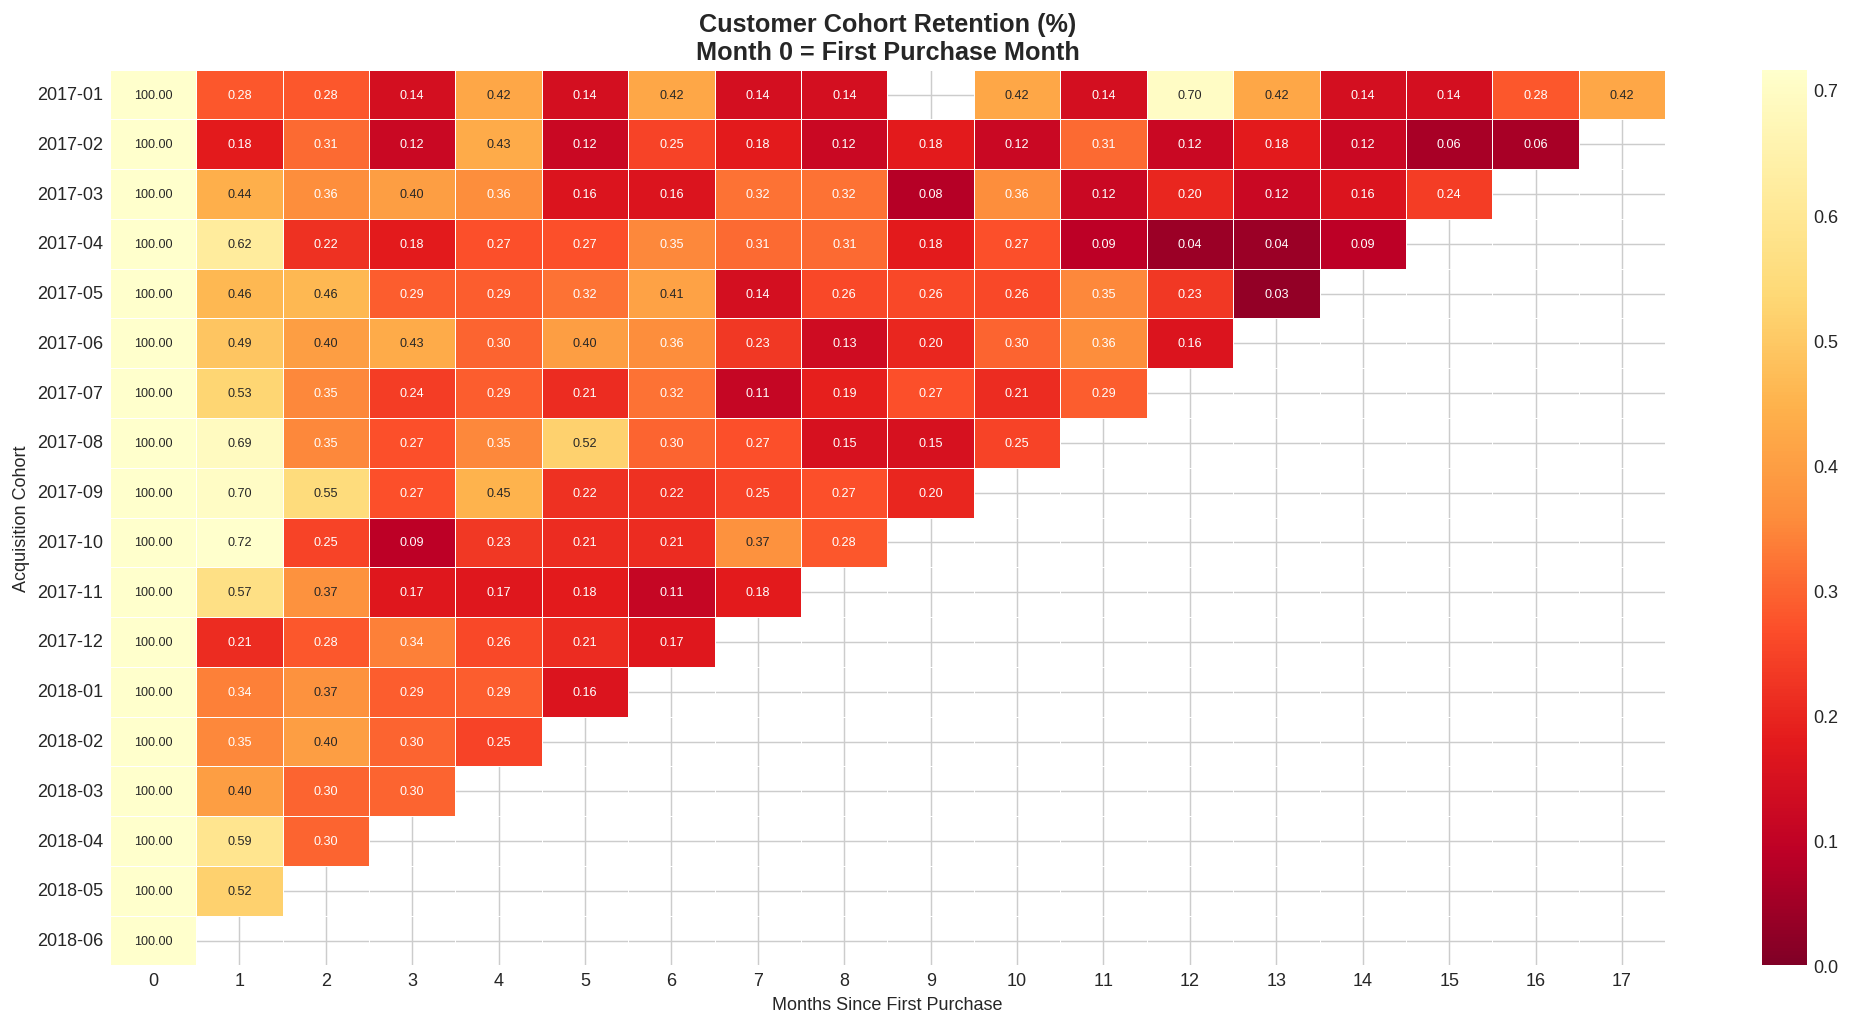

In [ ]:
# Assign cohort month - monh of first ever purchase
master_orders_stable['cohort_month'] = (master_orders_stable
                                        .groupby('customer_unique_id')['order_purchase_timestamp']
                                        .transform('min')
                                        .dt.to_period('M'))

master_orders_stable['order_period'] = (master_orders_stable['order_purchase_timestamp'].dt.to_period('M'))

master_orders_stable['cohort_index'] = (master_orders_stable['order_period'] -
                                        master_orders_stable['cohort_month']).apply(lambda x: x.n)

# Build a cohort table
cohort = (master_orders_stable
          .groupby(['cohort_month', 'cohort_index'])['customer_unique_id']
          .nunique()
          .reset_index()
          .pivot(index= 'cohort_month',
                 columns= 'cohort_index',
                 values= 'customer_unique_id'))

# Convert to retention percentages
cohort_pct = cohort.divide(cohort[0], axis=0) * 100
max_ret = cohort_pct.iloc[:,1:].max().max()
mean_ret = cohort_pct.iloc[:,1:].mean().mean()
print(f"Max retention (any month after 0): {max_ret:.2f}%")
print(f"Mean retention across all cohorts: {mean_ret:.2f}%")

fig, ax = plt.subplots(figsize= (16,8))
sns.heatmap(cohort_pct.round(2),
            annot=True, fmt= '.2f',
            cmap= 'YlOrRd_r',
            linewidths=0.4,
            annot_kws={'size': 7},
            ax=ax,
            vmin=0, vmax=max_ret)
ax.set_title('Customer Cohort Retention (%)\nMonth 0 = First Purchase Month',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Acquisition Cohort')
plt.tight_layout()
# plt.savefig('../charts/cohort_retention.png', dpi=150, bbox_inches='tight')
plt.show()

Month-1 retention pulled out as a column, so the trend across cohorts is readable without
scanning the heatmap.

In [ ]:
month1_retention = cohort_pct[1].dropna()
print("Month-1 Retention By Cohort:")
print(month1_retention.round(2))

Month-1 Retention By Cohort:
cohort_month
2017-01    0.28
2017-02    0.18
2017-03    0.44
2017-04    0.62
2017-05    0.46
2017-06    0.49
2017-07    0.53
2017-08    0.69
2017-09    0.70
2017-10    0.72
2017-11    0.57
2017-12    0.21
2018-01    0.34
2018-02    0.35
2018-03    0.40
2018-04    0.59
2018-05    0.52
Freq: M, Name: 1, dtype: float64


The specific comparison the acquisition analysis called for: does the Black Friday cohort
retain as well as the cohorts either side of it?

In [ ]:
# Black friday cohort specifically
nov_retention = cohort_pct.loc['2017-11', 1]
oct_retention = cohort_pct.loc['2017-10', 1]
print(f"\nOctober 2017 Month-1 retention: {oct_retention:.2f}%")
print(f"November 2017 Month-1 retention: {nov_retention:.2f}%")
print(f"Black Friday cohort underperformed October by: "
      f"{oct_retention - nov_retention:.2f} percentage points")

# Overall stats
print(f"\nMax Month-1 retention: {month1_retention.max():.2f}%")
print(f"Min Month-1 retention: {month1_retention.min():.2f}%")
print(f"Average Month-1 retention: {month1_retention.mean():.2f}%")


October 2017 Month-1 retention: 0.72%
November 2017 Month-1 retention: 0.57%
Black Friday cohort underperformed October by: 0.15 percentage points

Max Month-1 retention: 0.72%
Min Month-1 retention: 0.18%
Average Month-1 retention: 0.48%


## Finding — Customer Cohort Retention

Cohort retention analysis confirms that Olist operates with extremely
low but non-zero repeat purchase behaviour. Across all acquisition
cohorts, Month-1 retention ranges from 0.18% to 0.72%, with a mean
of 0.25% — meaning fewer than 1 in 150 customers returns the month
following their first purchase.

### Pattern 1 — Retention improved through 2017
The most encouraging signal in the heatmap is a consistent upward
trend in Month-1 retention across 2017: from 0.28% in January to
0.72% in October — a 157% improvement over 10 consecutive cohorts.
This suggests the platform was becoming meaningfully stickier as
its catalogue expanded and the customer experience matured. Each
cohort acquired later in 2017 was slightly more likely to return
than the one before it.

### Pattern 2 — Black Friday cohort underperforms
The November 2017 cohort — the largest single acquisition month
with 7,060 new customers — shows Month-1 retention of 0.57%,
noticeably below both October (0.72%) and September (0.70%).
This directly answers the question raised in the acquisition
analysis: Black Friday brings volume but not loyalty. The customers
acquired through promotional events are less likely to return than
those acquired organically in surrounding months, suggesting they
were primarily deal-seekers rather than habitual marketplace users.

### Pattern 3 — December collapse
December 2017 shows the lowest Month-1 retention of the entire
second half of 2017 at 0.21% — a sharp drop from November despite
similar acquisition volume. December buyers were likely purchasing
gifts for others rather than themselves, with no personal need to
return to the platform after the gifting occasion passed.

### Context — is this bad?
Sub-1% monthly retention sounds alarming but is structurally
consistent with a marketplace selling considered, infrequent
purchases (electronics, furniture, gifts). Customers don't buy
a new laptop every month. The more meaningful benchmark is
cumulative retention — across all months, 2,414 customers
(2.94%) did return at least once, with an average LTV of R$307
versus the one-time buyer average. The platform has a loyal
core — it's just a small one.

Business recommendation: the improving Month-1 retention trend
through 2017 (0.28% → 0.72%) suggests that organic platform
improvements are already moving the needle. Three targeted
interventions could accelerate this:

- Avoid over-investing in promotional acquisition (Black Friday)
  at the expense of organic acquisition — the data shows
  promotional cohorts retain worse, making their effective CAC
  higher than it appears when only counting acquisition cost

- Target December buyers specifically with a January
  re-engagement campaign — "buy something for yourself"
  messaging timed 30 days after delivery could recover some
  of the gift-buyers who have no personal category relationship
  with Olist yet

- Double down on whatever drove the September-October 2017
  retention improvement — if that period coincided with a
  product, UX, or catalogue change, replicating it would have
  compounding value across all future cohorts

---

# Section 4 · Geography

*Uses `master_orders_full` — geographic and delivery patterns are structural rather than
seasonal, so every delivered order adds precision here.*

## Q9 — Which states drive revenue, and how concentrated is it?

Revenue by state with a cumulative percentage column, which turns a ranking into a
concentration measure: how few states account for 80% of the business.

customer_state    revenue  orders  revenue_pct  cumulative_pct
            SP 5768324.25   40493    37.412434           37.41
            RJ 2055401.57   12350    13.331008           50.74
            MG 1818891.67   11354    11.797042           62.54
            RS  861278.79    5344     5.586117           68.13
            PR  781708.80    4923     5.070039           73.20
            SC  595127.78    3546     3.859904           77.06
            BA  591137.81    3256     3.834026           80.89
            DF  346123.35    2080     2.244901           83.14
            GO  334212.35    1957     2.167648           85.30
            ES  317657.93    1995     2.060279           87.36


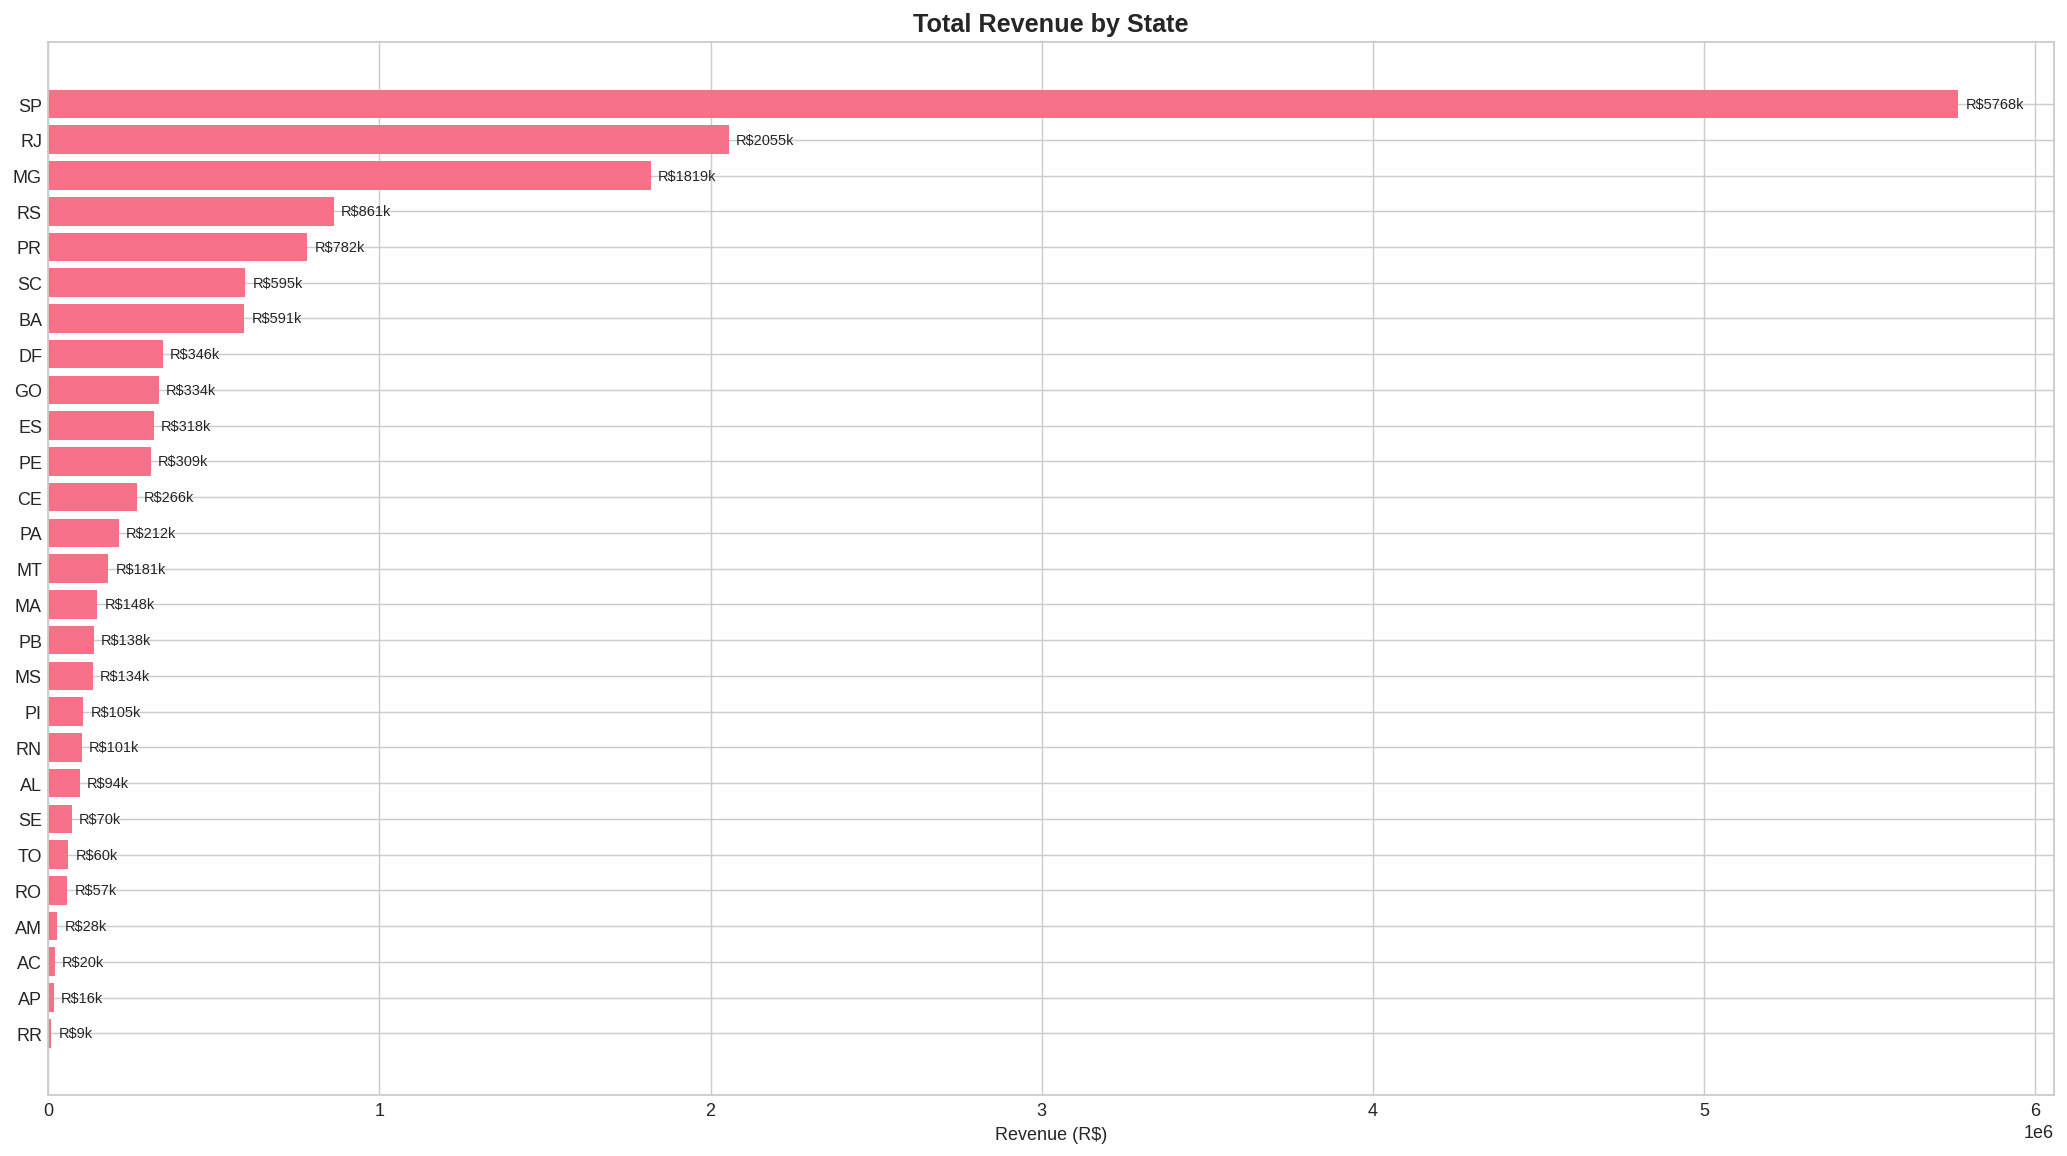

In [ ]:
state_stats = (master_orders_full
               .groupby('customer_state')
               .agg(revenue = ('total_revenue', 'sum'),
                    orders = ('order_id', 'count'),
                    aov = ('total_revenue', 'mean'),
                    avg_delivery = ('delivery_days', 'mean'))
               .reset_index()
               .sort_values('revenue', ascending=False))

# Add revenue percentage
state_stats['revenue_pct'] = state_stats['revenue']/state_stats['revenue'].sum() * 100

# Add cumulative percentage - shows Pareto concentration
state_stats['cumulative_pct'] = state_stats['revenue_pct'].cumsum().round(2)

print(state_stats[['customer_state','revenue','orders',
                    'revenue_pct','cumulative_pct']].head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(16,9))

bars = ax.barh(state_stats['customer_state'],
        state_stats['revenue'])
ax.bar_label(bars, labels= [f"R${v/1000:.0f}k" for v in state_stats['revenue']], padding = 4, fontsize = 8)
ax.set_title('Total Revenue by State', fontsize=14, fontweight='bold')
ax.set_xlabel('Revenue (R$)')
ax.invert_yaxis()
plt.tight_layout()
# plt.savefig('../charts/revenue_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

The Pareto numbers stated explicitly — top 3, top 5, and the number of states needed to
reach 80% of revenue.

In [ ]:
# Pareto concentration
top3_pct = state_stats.head(3)['revenue_pct'].sum()
top5_pct = state_stats.head(5)['revenue_pct'].sum()
states_for_80 = (state_stats['cumulative_pct'] <= 80).sum() + 1

print(f"Top 3 states: {top3_pct:.1f}% of revenue")
print(f"Top 5 states: {top5_pct:.1f}% of revenue")
print(f"States needed for 80% of revenue: {states_for_80} of 27")

Top 3 states: 62.5% of revenue
Top 5 states: 73.2% of revenue
States needed for 80% of revenue: 7 of 27


## Q10 — Do the biggest states also have the biggest baskets?

Revenue rank and average order value rank side by side. Ranking by total revenue answers
"where is the volume"; ranking by AOV answers "where is the spending power". They turn out
to be close to opposite.

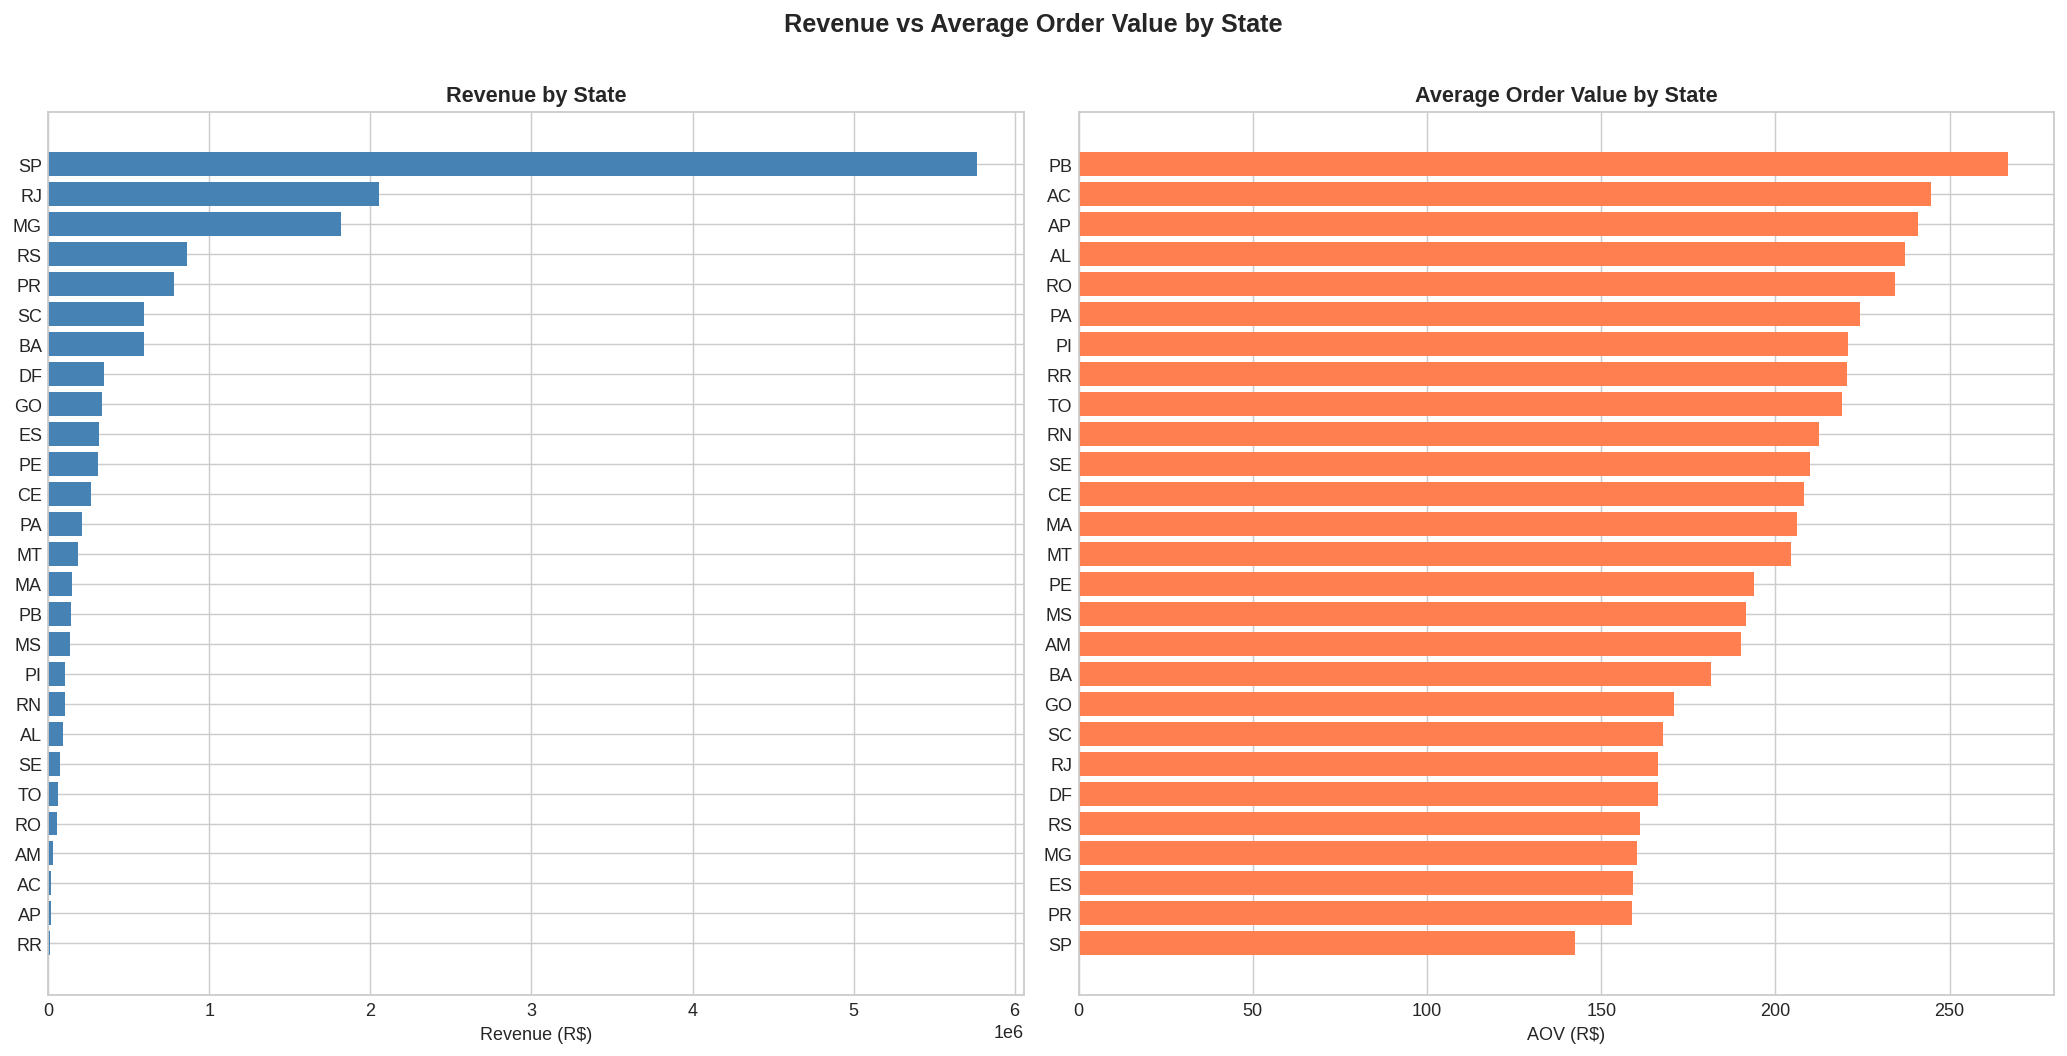

In [ ]:
# Chart 2 — AOV by state
state_aov = state_stats.sort_values('aov', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16,8))

# Left - Revenue Rank
axes[0].barh(state_stats['customer_state'],
             state_stats['revenue'], color = 'steelblue')
axes[0].set_title('Revenue by State', fontweight='bold')
axes[0].set_xlabel('Revenue (R$)')
axes[0].invert_yaxis()

# Right - AOV Rank
axes[1].barh(state_aov['customer_state'],
             state_aov['aov'], color = 'coral')
axes[1].set_title('Average Order Value by State', fontweight='bold')
axes[1].set_xlabel('AOV (R$)')
axes[1].invert_yaxis()

plt.suptitle("Revenue vs Average Order Value by State", fontsize = 14, fontweight = 'bold', y = 1.01)
plt.tight_layout()
# plt.savefig('../charts/state_revenue_vs_aov.png', dpi=150, bbox_inches='tight')
plt.show()


The AOV reversal quantified — the highest-AOV state against the highest-revenue state.

In [ ]:
# AOV comparison — SP vs top AOV states
sp_aov = state_stats[state_stats['customer_state'] == 'SP']['aov'].values[0]
pb_aov = state_stats[state_stats['customer_state'] == 'PB']['aov'].values[0]
print(f"SP AOV: R${sp_aov:.2f}")
print(f"PB AOV: R${pb_aov:.2f}")
print(f"PB customers spend {pb_aov/sp_aov:.1f}x more per order than SP customers")

# SP revenue dominance
sp_pct = state_stats[state_stats['customer_state'] == 'SP']['revenue_pct'].values[0]
print(f"\nSP alone: {sp_pct:.1f}% of total revenue")

SP AOV: R$142.45
PB AOV: R$266.61
PB customers spend 1.9x more per order than SP customers

SP alone: 37.4% of total revenue


## Finding — Geographic Revenue Distribution

### Strong Pareto concentration
Revenue is heavily concentrated in Brazil's southeastern states.
SP alone accounts for 37.4% of total revenue — approximately 3x
the next largest state (RJ at ~R$2M). The top 3 states (SP, RJ,
MG) collectively drive 62.5% of revenue, and just 7 states out
of 27 are needed to reach 80% of total revenue. This is a classic
Pareto distribution — a small geographic minority driving a large
majority of business outcomes.

### The AOV reversal — small states, big spenders
The most striking geographic insight emerges when comparing the
two charts side by side: the states that rank lowest by total
revenue rank highest by average order value. PB (Paraíba) customers
spend R\$266.61 per order on average — 1.9x more than SP customers
(R$142.45). AC, AP, AL, and RO follow the same pattern — remote
northern and northeastern states with low order volumes but
significantly higher spend per transaction.

This pattern has a logical explanation: customers in remote states
likely consolidate their online purchases into fewer, larger orders
to justify the higher shipping costs and longer delivery times
associated with their location. Rather than buying frequently in
small amounts, they buy infrequently but with higher basket sizes.

### SP's scale masks its efficiency
SP's near-bottom AOV ranking doesn't indicate low-value customers
— it reflects the opposite. SP customers have easy access to
physical retail and faster delivery, so they order more frequently
in smaller amounts rather than consolidating purchases. High
frequency × lower AOV = highest total revenue. This is a healthy
pattern for a marketplace, not a weakness.

Business recommendation: the geographic concentration in SP, RJ,
and MG creates both an opportunity and a risk:

- Opportunity: a 5% improvement in SP customer retention or
  acquisition directly translates to ~2% overall
  revenue growth — more impactful than the same effort applied
  to any other state

- Risk: geographic concentration means geographic fragility —
  a logistics disruption, economic shock, or strong competitor
  entering SP specifically would affect 37.4% of revenue
  immediately

- Hidden opportunity: northern/northeastern states (PB, AC, AP)
  show high AOV despite low volume, suggesting genuine purchasing
  power and willingness to spend. These markets are likely
  underpenetrated relative to their potential — targeted
  seller acquisition and category expansion in these states
  could yield disproportionate revenue per customer acquired

## Q11 — Which cities concentrate the most orders?

State-level analysis can hide urban concentration. Top 10 cities by order volume, labelled
with their state so the SP cluster is visible at a glance.

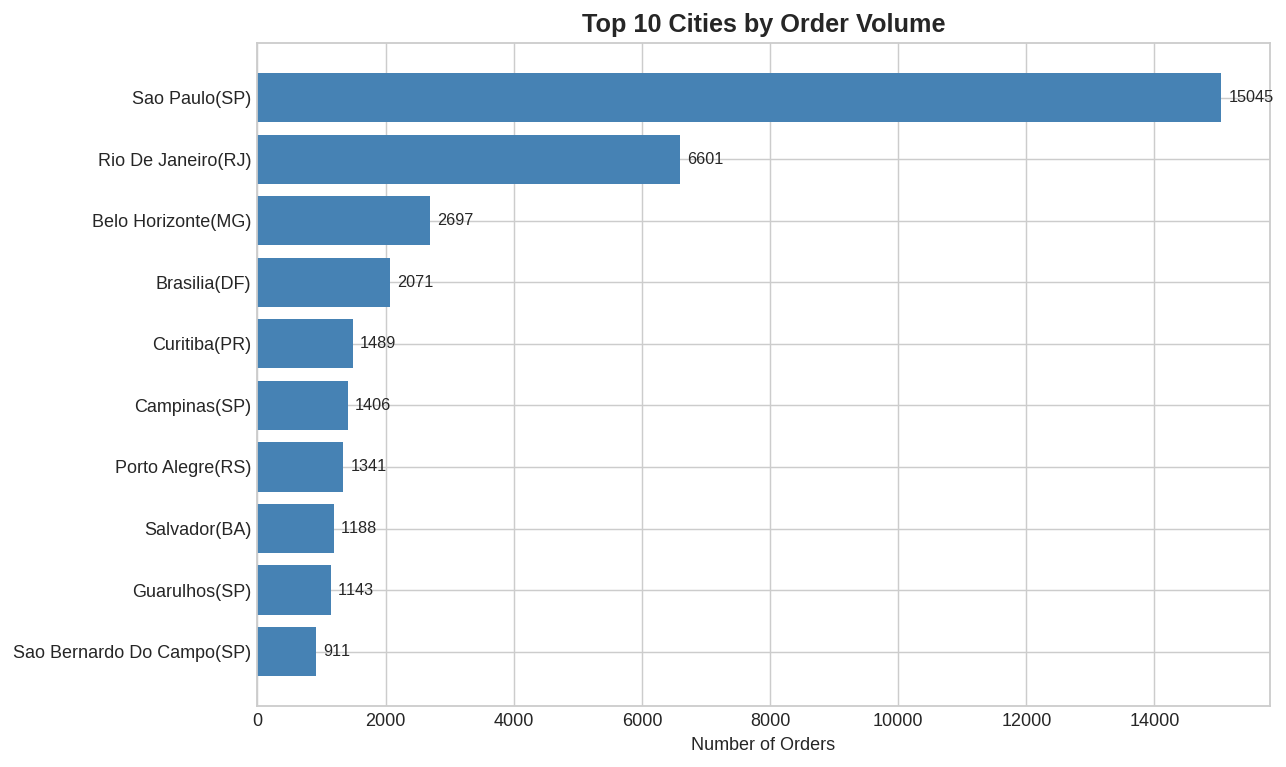

In [ ]:
# Chart 3 — Top 10 cities

city_stats = (master_orders_full
              .groupby(['customer_city', 'customer_state'])
              .agg(orders = ('order_id', 'count'),
                   revenue = ('total_revenue', 'sum'))
              .reset_index()
              .sort_values('orders', ascending=False)
              .head(10))

# Create readable label combining city + state
city_stats['city_label'] = city_stats['customer_city'].str.title() + '(' + city_stats['customer_state'] + ')'

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.barh(city_stats['city_label'], city_stats['orders'], color = 'steelblue')
ax.bar_label(bars, label = [f"{v:,}" for v in city_stats['orders']], padding = 4, fontsize = 9)
ax.set_title("Top 10 Cities by Order Volume", fontweight = 'bold', fontsize = 14)
ax.set_xlabel("Number of Orders")
ax.invert_yaxis()
plt.tight_layout()
# plt.savefig('../charts/top_10_cities.png', dpi=150, bbox_inches='tight')
plt.show()

City concentration as a share of all orders, including the combined weight of the four
SP-state cities that appear in the top 10.

In [ ]:
# Total orders in dataset for percentage calculations
total_orders = master_orders_full['order_id'].count()

# SP city alone as % of total
sp_city_pct = 15045 / total_orders * 100

# SP state cities in top 10 — count them
sp_cities_in_top10 = ['Sao Paulo', 'Campinas', 'Guarulhos', 'Sao Bernardo Do Campo']
sp_top10_orders = 15045 + 1406 + 1143 + 911
sp_top10_pct = sp_top10_orders / total_orders * 100

# SP city vs RJ city gap
gap = 15045 / 6601
print(f"Total orders: {total_orders:,}")
print(f"Sao Paulo city: {sp_city_pct:.1f}% of all orders")
print(f"SP state cities in top 10: {sp_top10_orders:,} orders ({sp_top10_pct:.1f}%)")
print(f"Sao Paulo city is {gap:.1f}x larger than Rio De Janeiro")

# Something interesting -- Brasilia (DF) ranks 4th
# DF is a federal district, not a state capital of a major state
# Worth flagging
brasilia_pct = 2071 / total_orders * 100
print(f"Brasilia: {brasilia_pct:.1f}% of orders — notable for a non-coastal city")

Total orders: 96,469
Sao Paulo city: 15.6% of all orders
SP state cities in top 10: 18,505 orders (19.2%)
Sao Paulo city is 2.3x larger than Rio De Janeiro
Brasilia: 2.1% of orders — notable for a non-coastal city


## Finding — Top 10 Cities by Order Volume

### São Paulo's dominance at city level is even more extreme
Sao Paulo city alone accounts for 15.6% of all orders at 15,045 —
2.3x more than the second largest city Rio De Janeiro (6,601). The
gap between these two is larger than the gap between Rio De Janeiro
and every other city on the list combined, confirming that Olist's
order activity is not just state-concentrated but specifically
city-concentrated within SP state.

### SP state owns 4 of the top 10 cities
Sao Paulo, Campinas, Guarulhos, and Sao Bernardo Do Campo — all
within SP state — together account for 18,505 orders (19.2% of
total). This means SP state's dominance seen in the state-level
chart is driven primarily by its urban concentration rather than
being spread evenly across the state.

### Brasilia punches above its weight
Brasilia (DF) ranking 4th with 2,071 orders is notable — it is
neither a coastal city nor part of the traditional SP-RJ-MG
economic corridor. As Brazil's capital and a planned city with
high per-capita income and government employment, it represents
a distinct premium urban market that the state-level chart
partially obscures under the DF label.

### Cities 5-10 are tightly clustered
Curitiba, Campinas, Porto Alegre, Salvador, Guarulhos, and Sao
Bernardo Do Campo all sit in a relatively tight range of 911–1,489
orders — none dramatically outperforms the others. This suggests
no single secondary city has achieved the kind of market penetration
that Sao Paulo has, leaving room for targeted city-level expansion.

Business recommendation: the 4-city SP cluster and Rio De Janeiro
represent the most efficient targets for any city-specific
initiatives — seller acquisition campaigns, same-day delivery
pilots, or logistics hub investments would reach the highest
customer density per R$ spent in these markets. Brasilia warrants
separate attention as a high-income market that may respond well
to premium category promotion (watches_gifts, computers) given its
government and professional employment base.

## Q12 — How long does delivery actually take, and where is it worst?

A boxplot rather than a bar chart, deliberately: the median tells you the typical
experience, but the spread tells you how *predictable* it is — and unpredictable delivery
damages trust more than consistently slow delivery. Restricted to the top 10 states by
volume for readability, with an overall median reference line.

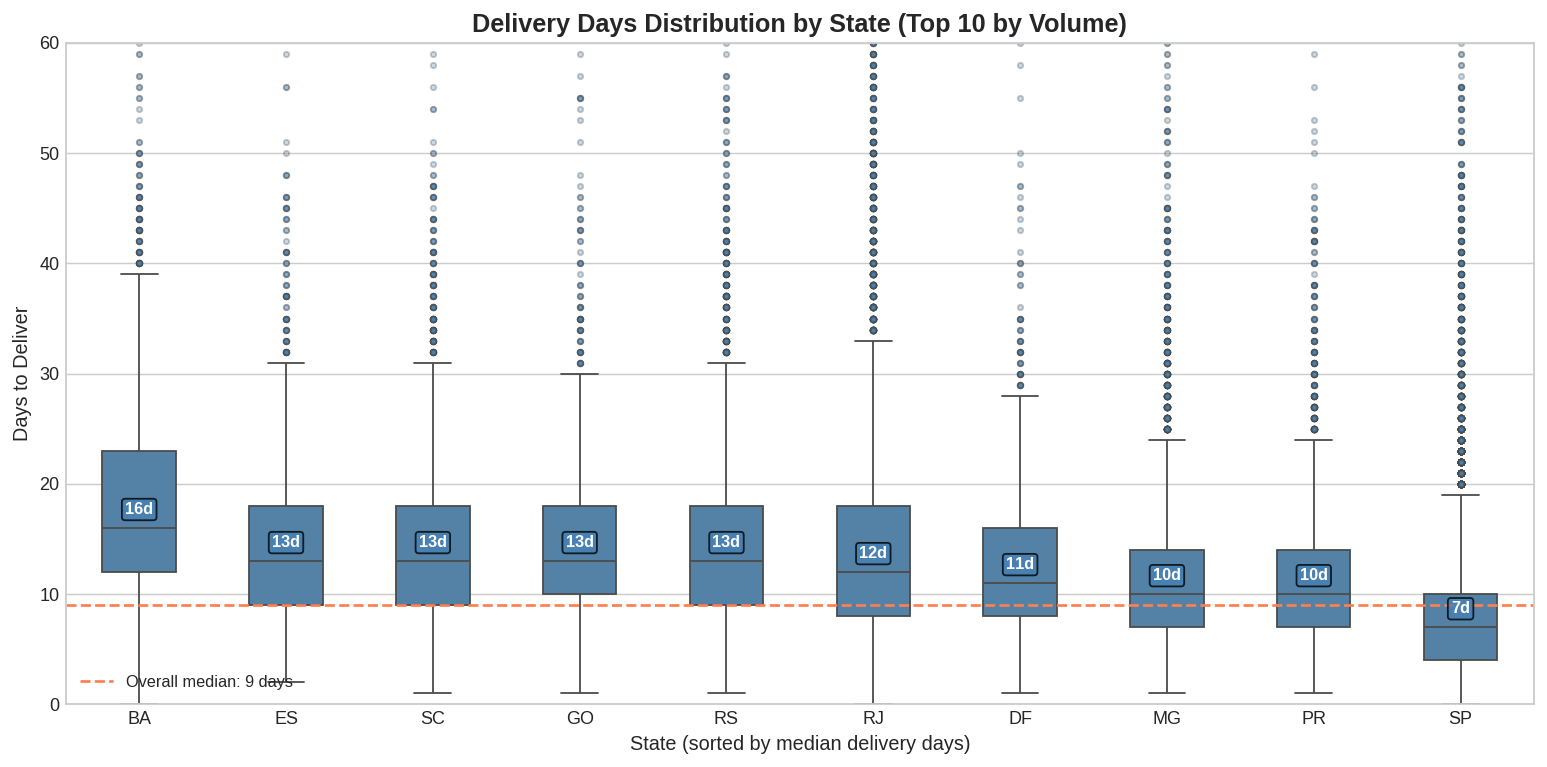

Median delivery days by state (top 10, slowest to fastest):
customer_state
BA    16.0
ES    13.0
SC    13.0
GO    13.0
RS    13.0
RJ    12.0
DF    11.0
MG    10.0
PR    10.0
SP     7.0
Name: delivery_days, dtype: float64

Overall median delivery: 9.0 days
Fastest state median: 7.0 days
Slowest state median: 16.0 days


In [ ]:
# Chart 4 — Delivery days by state

# Top 10 states by order volume for readability
top10_states = state_stats.head(10)['customer_state'].tolist()
delivery_data = master_orders_full[master_orders_full['customer_state'].isin(top10_states)].copy()

# Sort states by median delivery days for cleaner visual
state_order = (delivery_data
               .groupby('customer_state')['delivery_days']
               .median()
               .sort_values(ascending = False)
               .index
               .tolist())

fig, ax = plt.subplots(figsize=(12,6))

sns.boxplot(data = delivery_data,
            x = 'customer_state',
            y = 'delivery_days',
            order = state_order,
            color = 'steelblue',
            width = 0.5,
            flierprops = dict(marker = 'o', markerfacecolor = 'steelblue', markersize = 3, alpha= 0.3),
            ax = ax)

# Add median labels above each box
medians = (delivery_data
           .groupby('customer_state')['delivery_days']
           .median()
           .reindex(state_order))

for i, median in enumerate(medians):
  ax.text(i, median + 1, f"{median:.0f}d",
          va = 'bottom', ha = 'center',
          fontsize = 9, fontweight = 'bold', color = 'white',
          bbox = dict(boxstyle = 'round', pad = 0.2, facecolor = 'steelblue', alpha = 0.8))

ax.set_title('Delivery Days Distribution by State (Top 10 by Volume)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('State (sorted by median delivery days)', fontsize=11)
ax.set_ylabel('Days to Deliver', fontsize=11)
ax.set_ylim(0, 60)
ax.axhline(y=delivery_data['delivery_days'].median(),
           color='coral', linestyle='--', linewidth=1.5,
           label=f"Overall median: {delivery_data['delivery_days'].median():.0f} days")
ax.legend(fontsize=9)

plt.tight_layout()
# plt.savefig('../charts/delivery_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

# Key stats
print("Median delivery days by state (top 10, slowest to fastest):")
print(delivery_data.groupby('customer_state')['delivery_days']
      .median().sort_values(ascending=False).round(1))

print(f"\nOverall median delivery: {delivery_data['delivery_days'].median():.1f} days")
print(f"Fastest state median: {delivery_data.groupby('customer_state')['delivery_days'].median().min():.1f} days")
print(f"Slowest state median: {delivery_data.groupby('customer_state')['delivery_days'].median().max():.1f} days")


The same median calculation across all 27 states, to catch the slow states that sit
outside the top 10 by volume.

In [ ]:
# All states ranked by median delivery
all_state_delivery = (master_orders_full
    .groupby('customer_state')['delivery_days']
    .median()
    .sort_values(ascending=False))

print("Slowest 5 states by median delivery:")
print(all_state_delivery.head(5).round(1))

print("\nFastest 5 states by median delivery:")
print(all_state_delivery.tail(5).round(1))

Slowest 5 states by median delivery:
customer_state
AM    25.0
RR    25.0
AP    24.0
AL    22.0
PA    21.0
Name: delivery_days, dtype: float64

Fastest 5 states by median delivery:
customer_state
RJ    12.0
DF    11.0
MG    10.0
PR    10.0
SP     7.0
Name: delivery_days, dtype: float64


The fastest-to-slowest gap stated as both a difference in days and a multiple.

In [ ]:
# SP vs slowest state gap
sp_median = 7
am_median = 25
gap_multiplier = am_median / sp_median
gap_days = am_median - sp_median

# How many states are above vs below overall median
overall_median = 9
above_median = (all_state_delivery > overall_median).sum()
below_median = (all_state_delivery <= overall_median).sum()

print(f"SP to AM gap: {gap_days} days ({gap_multiplier:.1f}x longer)")
print(f"States slower than overall median: {above_median}")
print(f"States faster than or equal: {below_median}")

# BA is the slowest in top 10 -- how much slower than SP?
ba_sp_gap = 16 - 7
print(f"BA vs SP gap: {ba_sp_gap} days — {16/7:.1f}x longer than SP")

SP to AM gap: 18 days (3.6x longer)
States slower than overall median: 26
States faster than or equal: 1
BA vs SP gap: 9 days — 2.3x longer than SP


## Finding — Delivery Days Distribution by State

### SP defines the benchmark — everyone else is slower
São Paulo delivers in a median of 7 days — and it is the only
state in Brazil at or below the overall median of 9 days. All
other 26 states deliver slower than the national median, which
is itself heavily influenced by SP's enormous order volume
(40%+ of all transactions). In other words, Olist's "average"
delivery experience is essentially SP's delivery experience —
customers in every other state are getting a below-average
experience by definition.

### The north-south divide is extreme
The gap between the fastest and slowest states is 18 days —
SP at 7 days vs AM and RR at 25 days each. Customers in
Amazonas wait 3.6x longer for their orders than customers in
São Paulo. AP (24d), AL (22d), and PA (21d) follow closely.
This isn't a marginal operational difference — it is a
fundamentally different customer experience depending on
where you live in Brazil.

### Within top 10 states, BA stands out
Even among high-volume states, BA is notably slower at 16
days — 2.3x longer than SP and 7 days above the cluster
of states sitting at 12-13 days (ES, SC, GO, RS, RJ).
BA is geographically large and has infrastructure challenges
relative to the southeastern states, making it an outlier
even within Olist's most active markets.

### Every state has extreme outliers
Every boxplot shows outlier dots clustered near the 60-day
cap — meaning no state is immune to occasional very long
deliveries. Even SP, with its 7-day median, has orders
that took 50+ days. These represent seller fulfilment
failures, remote addresses, or customs issues rather
than systemic last-mile problems — but they exist
everywhere and affect review scores regardless of cause.

### Box width reveals consistency problems
BA and ES show wider boxes than SP and PR — meaning higher
delivery time variance. SP customers know to expect roughly
7 days. BA customers might receive in 10 days or 25 days
with similar probability. Unpredictable delivery damages
customer trust more than consistently slow delivery, because
customers cannot plan around uncertainty.

Business recommendation: three distinct priorities emerge:

- SP and PR (7-10 day medians, narrow boxes) are candidates
  for same-day or next-day delivery pilots — the logistics
  infrastructure already supports faster tiers with
  incremental investment

- Northern states (AM, RR, AP — 24-25 day medians) warrant
  urgent logistics partnership review. Critically, these
  same states showed the highest AOV in the geographic
  revenue analysis — customers willing to spend R$240-260
  per order are being asked to wait 25 days for delivery.
  That combination of high spend willingness and poor
  delivery experience is the highest-leverage improvement
  opportunity in the entire dataset

- High-variance states (BA, ES) need consistency
  improvements before speed improvements — narrowing the
  delivery time spread matters more than reducing the
  median, since a customer who sometimes waits 25 days
  and sometimes 10 days has a worse experience than one
  who consistently waits 15 days and can plan accordingly

---

# Section 5 · RFM customer segmentation

*Uses `master_orders_stable`, aggregated on `customer_unique_id`.*

RFM scores every customer on three behavioural dimensions and turns them into segments
that map directly onto marketing actions:

| Dimension | Question | Measured as |
|---|---|---|
| **Recency** | how recently did they buy? | days since last order (lower is better) |
| **Frequency** | how often do they buy? | distinct orders |
| **Monetary** | how much do they spend? | total revenue |

Each dimension is scored 1–5 by quintile, so scores are relative to Olist's own customer
base rather than to an arbitrary external benchmark. Recency is scored in reverse — the
most recent buyers get 5.

## Q13 — Which customers are most valuable, and which are slipping away?

### Building the RFM table

The reference date is one day after the last order in the stable period, so recency is
measured against "today" from the dataset's point of view rather than against the real
current date.

In [ ]:
# Reference date — 1 day after last order in stable period
reference_date = (master_orders_stable['order_purchase_timestamp'].max() + pd.Timedelta(days = 1))

# Build RFM at customer level using customer_unique_id
rfm = (master_orders_stable
       .groupby('customer_unique_id')
       .agg(recency = ('order_purchase_timestamp',
                       lambda x: (reference_date - x.max()).days),
            frequency = ('order_id', 'nunique'),
            monetary = ('total_revenue', 'sum'))
       .reset_index())

print(f"RFM table shape: {rfm.shape}")
print(f"\nRFM summary:")
print(rfm[['recency','frequency','monetary']].describe().round(2))

RFM table shape: (81005, 4)

RFM summary:
        recency  frequency  monetary
count  81005.00   81005.00  81005.00
mean     208.79       1.03    164.91
std      136.71       0.21    224.16
min        1.00       1.00     10.07
25%       96.00       1.00     63.10
50%      191.00       1.00    107.78
75%      308.00       1.00    182.38
max      542.00      10.00  13664.08


Checking the distribution of each dimension before scoring — particularly frequency, which
is where this dataset departs from the textbook.

In [ ]:
# Check frequency distribution in detail
print("Frequency value counts:")
print(rfm['frequency'].value_counts().sort_index())

# What % of customers have frequency = 1?
freq_1_pct = (rfm['frequency'] == 1).sum() / len(rfm) * 100
print(f"\nCustomers with frequency = 1: {freq_1_pct:.1f}%")

# Check monetary distribution
print(f"\nMonetary percentiles:")
print(rfm['monetary'].quantile([0.1,0.25,0.5,0.75,0.9,0.95,0.99]).round(2))

Frequency value counts:
frequency
1     78591
2      2216
3       157
4        23
5         9
6         4
7         3
9         1
10        1
Name: count, dtype: int64

Customers with frequency = 1: 97.0%

Monetary percentiles:
0.10      40.09
0.25      63.10
0.50     107.78
0.75     182.38
0.90     318.33
0.95     466.94
0.99    1093.49
Name: monetary, dtype: float64


> **Note on the Frequency dimension:** 97% of Olist customers have placed exactly 1 order,
> making the F dimension largely a noise variable in this dataset. F scores within the
> one-time buyer group are distributed based on rank position rather than meaningful
> behavioral differences. The primary drivers of segmentation in this model are therefore
> Recency and Monetary. A two-dimensional RM model would be equally valid for this dataset
> — the full RFM is retained here for framework completeness and comparability with
> industry standard approaches.

### Handling the monetary outliers

A handful of very large orders would otherwise pull the quintile boundaries upward and
squash the top segments. Capping at the 99th percentile keeps those customers in the
analysis and in the revenue totals, while stopping them from distorting the score
cut-offs.

In [ ]:
# Cap monetary at 99th percentile before scoring
# Preserves the outlier in the data but prevents it from
# distorting quintile boundaries

monetary_cap = rfm['monetary'].quantile(0.99)
rfm['monetary_capped'] = rfm['monetary'].clip(upper = monetary_cap)

print(f"Monetary capped at 99th percentile: R${monetary_cap:.2f}")
print(f"Customers affected by cap: "
      f"{(rfm['monetary'] > monetary_cap).sum():,}")

Monetary capped at 99th percentile: R$1093.49
Customers affected by cap: 811


### Scoring

`pd.qcut` splits each dimension into five equal-sized groups. The recency labels are
reversed (`[5,4,3,2,1]`) because a low recency value is good. `.rank(method='first')` is
applied to frequency and monetary to break the ties that would otherwise make `qcut` fail
on this heavily-tied data.

`rm_score` deliberately sums R and M only, for the reason set out in the note above.

In [ ]:
rfm['R'] = pd.qcut(rfm['recency'], q = 5,
                   labels = [5,4,3,2,1]).astype(int)

# Keeping F just for framework completeness
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5,
                    labels=[1,2,3,4,5]).astype(int)

rfm['M'] = pd.qcut(rfm['monetary_capped'].rank(method='first'), q = 5,
                   labels = [1,2,3,4,5]).astype(int)

rfm['rm_score'] = rfm['R'] + rfm['M']
print(f"RM score range: {rfm['rm_score'].min()} to {rfm['rm_score'].max()}")
print(f"Score distribution:")
print(rfm['rm_score'].value_counts().sort_index())


RM score range: 2 to 10
Score distribution:
rm_score
2      3392
3      6445
4      9958
5     12719
6     15877
7     12591
8     10001
9      6618
10     3404
Name: count, dtype: int64


### Segment definitions

Five segments derived from the R and M scores, evaluated in priority order:

| Segment | Rule | Meaning |
|---|---|---|
| **Champions** | R ≥ 4 and M ≥ 4 | bought recently, spend the most — protect |
| **Loyal** | R ≥ 3 and M ≥ 3 | solid on both — nurture |
| **Potential** | R ≥ 3 | recent but low spend — grow |
| **At Risk** | M ≥ 3 | high spend, long since gone — win back |
| **Lost** | everything else | low on both — deprioritise |

The order of the `if` branches *is* the logic: a customer who qualifies for a stronger
segment never falls through to a weaker one.

In [ ]:
# Segmentation on R + M Score

def assign_segment(row):
  r , m = row['R'], row['M']
  if r >= 4 and m >= 4:   return 'Champions'
  elif r >= 3 and m >= 3: return 'Loyal'
  elif r >= 3:            return 'Potential'
  elif m >= 3:            return 'At Risk'
  else:                   return 'Lost'

rfm['segment'] = rfm.apply(assign_segment, axis = 1)


Validating that the segments behave the way their definitions claim — Champions should
show low recency and high spend, Lost the opposite.

In [ ]:
# Verify the segment distribution makes intuitive sense
print(rfm['segment'].value_counts())

# Also check: do Champions have higher R and M than Lost?
print(rfm.groupby('segment')[['R','M','recency','monetary']].mean().round(2))

segment
Potential    19052
At Risk      18964
Loyal        16208
Champions    13431
Lost         13350
Name: count, dtype: int64
              R     M  recency  monetary
segment                                 
At Risk    1.51  4.01   349.28    244.28
Champions  4.51  4.49    76.87    301.48
Lost       1.49  1.51   352.64     55.77
Loyal      3.62  3.58   143.33    178.47
Potential  3.98  1.49   116.84     54.58


### Segment summary — size against value

Customer count and revenue share per segment. The gap between those two columns is where
the actionable insight lives.

In [ ]:
# Segment summary table
seg_order = ['Champions', 'Loyal', 'Potential', 'At Risk', 'Lost']

seg_summary = (rfm
               .groupby('segment')
               .agg(
                   customers = ('customer_unique_id', 'count'),
                   avg_recency = ('recency', 'mean'),
                   avg_monetary = ('monetary', 'mean'),
                   avg_frequency = ('frequency', 'mean'),
                   total_revenue = ('monetary', 'sum')
               )
               .reindex(seg_order).reset_index())

seg_summary['customer_pct'] = (
    seg_summary['customers'] / seg_summary['customers'].sum() * 100
).round(1)

seg_summary['revenue_pct'] = (
    seg_summary['total_revenue'] / seg_summary['total_revenue'].sum() * 100
).round(1)

print(seg_summary.to_string(index=False))


  segment  customers  avg_recency  avg_monetary  avg_frequency  total_revenue  customer_pct  revenue_pct
Champions      13431    76.865758    301.475495       1.078550     4049117.38          16.6         30.3
    Loyal      16208   143.334711    178.473456       1.039178     2892697.77          20.0         21.7
Potential      19052   116.841224     54.582019       1.004356     1039896.63          23.5          7.8
  At Risk      18964   349.275047    244.278268       1.044347     4632493.08          23.4         34.7
     Lost      13350   352.641498     55.772591       1.005693      744564.09          16.5          5.6


Revenue per customer by segment, plus two sizing calculations: how much revenue sits in
the At Risk and Lost segments, and what moving Potential customers up to the Loyal average
spend would be worth.

In [ ]:
# Champions revenue per customer vs others
champ_rev_per_customer = 4049117 / 13431
at_risk_rev_per_customer = 4632493 / 18964
lost_rev_per_customer = 744564 / 13350
potential_rev_per_customer = 1039896 / 19052

print(f"Revenue per customer:")
print(f"Champions:  R${champ_rev_per_customer:.2f}")
print(f"At Risk:    R${at_risk_rev_per_customer:.2f}")
print(f"Potential:  R${potential_rev_per_customer:.2f}")
print(f"Lost:       R${lost_rev_per_customer:.2f}")

# What % of revenue is at risk of being lost?
# At Risk + Lost combined
at_risk_lost_rev = 4632493 + 744564
total_rev = 4049117 + 2892697 + 1039896 + 4632493 + 744564
print(f"\nAt Risk + Lost revenue: R${at_risk_lost_rev:,.0f} "
      f"({at_risk_lost_rev/total_rev*100:.1f}% of total)")

# Potential upside -- if Potential customers doubled their spend
potential_upside = 19052 * (178 - 55)  # bring to Loyal avg monetary
print(f"\nIf Potential customers reached Loyal avg spend:")
print(f"Incremental revenue: R${potential_upside:,.0f}")

Revenue per customer:
Champions:  R$301.48
At Risk:    R$244.28
Potential:  R$54.58
Lost:       R$55.77

At Risk + Lost revenue: R$5,377,057 (40.3% of total)

If Potential customers reached Loyal avg spend:
Incremental revenue: R$2,343,396


### Charts — segment size, segment value, and the Recency/Monetary space

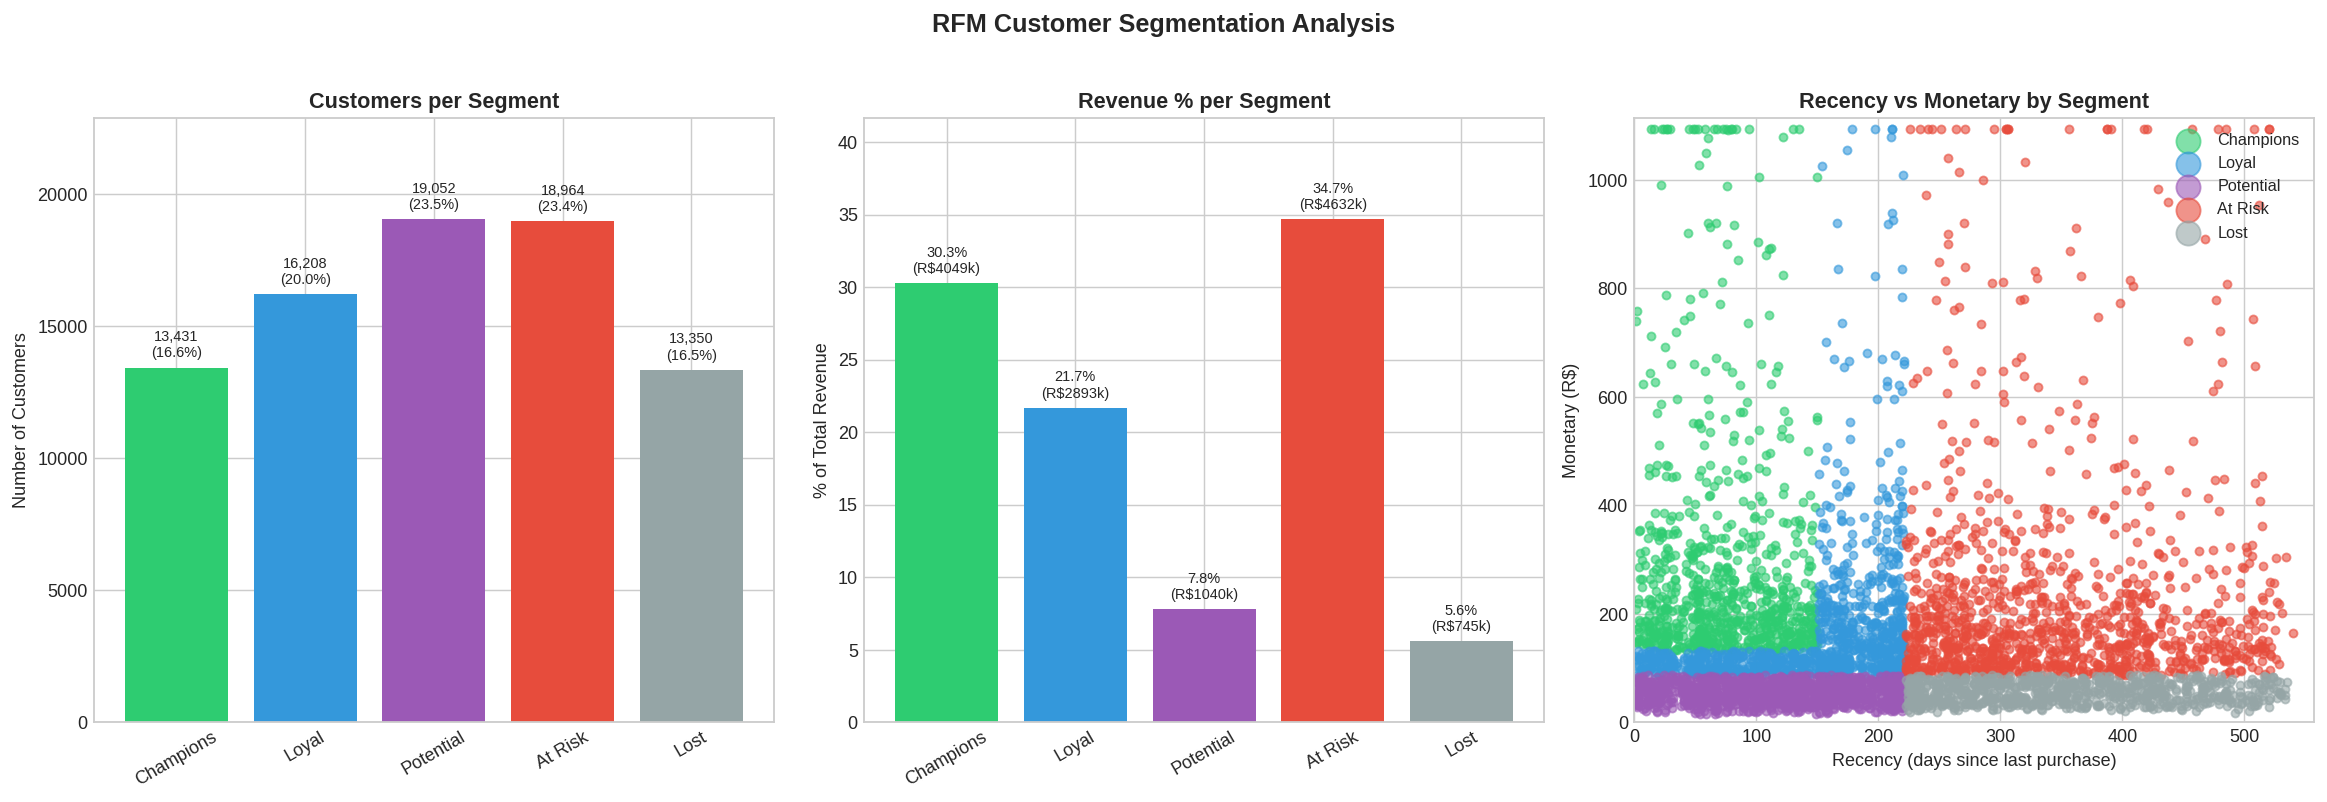

In [ ]:
# Charts

colors_map = {
    'Champions': '#2ecc71',
    'Loyal':     '#3498db',
    'Potential': '#9b59b6',
    'At Risk':   '#e74c3c',
    'Lost':      '#95a5a6'
}

colors = [colors_map[s] for s in seg_order]

fig, axes = plt.subplots(1, 3, figsize=(18,6))

# Chart 1- Customer Count
seg_plot = seg_summary.set_index('segment').reindex(seg_order)
bars = axes[0].bar(seg_order, seg_plot['customers'], color = colors)
axes[0].bar_label(bars,
                  labels = [f"{x:,}\n({y:.1f}%)" for x, y in zip(seg_plot['customers'], seg_plot['customer_pct'])],
                  padding = 4, fontsize = 8)
axes[0].set_title('Customers per Segment', fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0, seg_plot['customers'].max() * 1.2)

# Chart 2 - Revenue Contribution
bars2 = axes[1].bar(seg_order, seg_plot['revenue_pct'], color = colors)
axes[1].bar_label(bars2,
                  labels = [f"{x:.1f}%\n(R${y/1000:.0f}k)" for x, y in zip(seg_plot['revenue_pct'], seg_plot['total_revenue'])],
                  padding = 4, fontsize = 8)
axes[1].set_title('Revenue % per Segment', fontweight='bold')
axes[1].set_ylabel('% of Total Revenue')
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylim(0, seg_plot['revenue_pct'].max() * 1.2)

# Chart 3 - Recency vs Monetary scatter
sample = rfm.sample(min(5000, len(rfm)), random_state = 42)
for seg in seg_order:
  grp = sample[sample['segment'] == seg]
  axes[2].scatter(grp['recency'], grp['monetary_capped'],
                  alpha = 0.6, label = seg, s = 20, color = colors_map[seg])
axes[2].set_title('Recency vs Monetary by Segment',
                   fontweight='bold')
axes[2].set_xlabel('Recency (days since last purchase)')
axes[2].set_ylabel('Monetary (R$)')
axes[2].legend(fontsize=9,
               markerscale=3,
               loc='upper right',
               framealpha=0.9,
               edgecolor='lightgrey')

axes[2].set_xlim(0, rfm['recency'].max() + 15)
axes[2].set_ylim(0, rfm['monetary_capped'].max() + 20)
plt.suptitle('RFM Customer Segmentation Analysis',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
# plt.savefig('../charts/rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()


Exporting the segmented customer table. This CSV is the input for the Power BI customer
segments page and for the later stages of the project, so the segmentation is computed
once here and reused everywhere else.

In [ ]:
rfm.to_csv('/content/clean/rfm_segments.csv', index=False)
print(f"Exported: {rfm.shape[0]:,} customers")
print(rfm['segment'].value_counts())

Exported: 81,005 customers
segment
Potential    19052
At Risk      18964
Loyal        16208
Champions    13431
Lost         13350
Name: count, dtype: int64


## Finding — RFM Customer Segmentation

### Segmentation validation
The RM model produces behaviorally coherent segments confirmed
by the validation table. Champions show the highest R and M
scores (4.51 and 4.49 respectively) with avg recency of just
77 days and avg spend of R\$301 . Lost customers sit at the
opposite extreme - R=1.49, M=1.51, avg recency 353 days,
avg spend R\$56. The model is working correctly.

### The counterintuitive revenue story
The most striking finding is that At Risk customers drive MORE
total revenue (34.7%, R\$4.6M) than Champions (30.3%, R\$4.0M)
— despite having an average recency of 349 days (nearly a year
since last purchase). This is not because At Risk customers
are currently active — they're not. It reflects their
historical high-value purchases (avg monetary R\$244, M=4.01)
before they churned. They were Olist's best customers. They
left. Their past spend still shows up in the revenue totals.

At a per-customer level the picture is clearer:
- Champions:  R\$301.5 revenue per customer
- At Risk:    R\$244.3 revenue per customer
- Potential:  R\$54.6 revenue per customer
- Lost:       R\$55.8 revenue per customer

### The revenue concentration problem
Champions and At Risk together account for 40% of
customers but 65% of total revenue. At Risk
and Lost combined represent R$5.4M — 40.3% of total revenue
— that is either already lost or at severe risk of being lost
permanently.

### The Potential opportunity
Potential is the largest segment at 23.5% of customers (19,052)
but generates only 7.8% of revenue — the biggest gap between
customer share and revenue share of any segment. These customers
bought recently (avg recency 117 days, R=3.98) but spent very
little (avg R\$55, M=1.49). They are engaged with the platform
but haven't discovered higher-value categories yet. If each
Potential customer could be nudged to the Loyal average spend
(R\$178), the incremental revenue opportunity is approximately
R$2,343,396 — without acquiring a single new customer.

### Note on Frequency dimension
97% of Olist customers have placed exactly 1 order, making the
F dimension a noise variable in this dataset. Frequency scores
within the one-time buyer group reflect dataframe position
rather than meaningful behavioral differences. This RM model
is therefore driven entirely by Recency and Monetary, which
carry all the genuine signal in this dataset. A traditional
3-dimension RFM model would produce identical results here
since F adds no discriminating power.

Business recommendation:

- Champions (16.6% of customers, 30.3% of revenue): protect
  at all costs. These 13,431 customers are responsible for
  nearly a third of all revenue. Even losing 10% of them
  means losing R$400k+ in revenue. Priority actions: exclusive
  early access to new products, loyalty recognition, personal
  thank-you communications. Do not discount — they already
  buy at full price.

- At Risk (23.4% of customers, 34.7% of revenue): the highest
  urgency segment. These were your best customers and are now
  lapsing. An avg recency of 349 days means most haven't bought
  in nearly a year. A targeted win-back campaign with a
  personalised offer based on their previous category purchases
  (they likely bought from health_beauty or watches_gifts given
  their high avg spend) could recover even 5% of this segment
  — approximately R$230k in incremental revenue.

- Potential (23.5% of customers, 7.8% of revenue): the growth
  engine. Recent, engaged, but low-spend. Category expansion
  is the lever — show them health_beauty or computers_accessories
  based on their first purchase. The goal is first cross-sell,
  not deep discounting. They bought recently which means they
  trust the platform — capitalize on that recency window before
  it closes.

- Lost (16.5% of customers, 5.6% of revenue): low priority
  for individual win-back given avg spend of R$56. A single
  low-cost mass email campaign is the maximum justified
  investment. Accept that most are genuinely gone.

---

# Section 6 · Reviews

*Uses `master_orders_full` — review behaviour is not time-sensitive the way revenue is, and
the full dataset maximises review coverage.*

## Q14 — How satisfied are customers, and what actually drives satisfaction?

Three things at once: the shape of the score distribution, the relationship between
delivery speed and score, and how satisfaction differs across the RFM segments built in
Section 5.

### Attaching segments to orders

The RFM table is customer-level and the orders table is order-level, so a left merge on
`customer_unique_id` carries the segment down to every order. Orders from the soft-launch
months have no segment — expected, since RFM was built on the stable period only.

In [ ]:
# Reviews section uses master_orders_full (not stable)
# because reviews aren't time-sensitive the same way revenue is
# and you want maximum review coverage

master_orders_rfm = master_orders_full.merge(
    rfm[['customer_unique_id', 'segment', 'R', 'M', 'monetary_capped']],
    on = 'customer_unique_id',
    how = 'left'
)

print(f"master_orders_rfm shape: {master_orders_rfm.shape}")
print(f"Rows with segment assigned: {master_orders_rfm['segment'].notna().sum():,}")
print(f"Rows without segment (soft launch orders): "
      f"{master_orders_rfm['segment'].isna().sum():,}")

master_orders_rfm shape: (96469, 28)
Rows with segment assigned: 83,997
Rows without segment (soft launch orders): 12,472


### Charts — score distribution, delivery impact, and satisfaction by segment

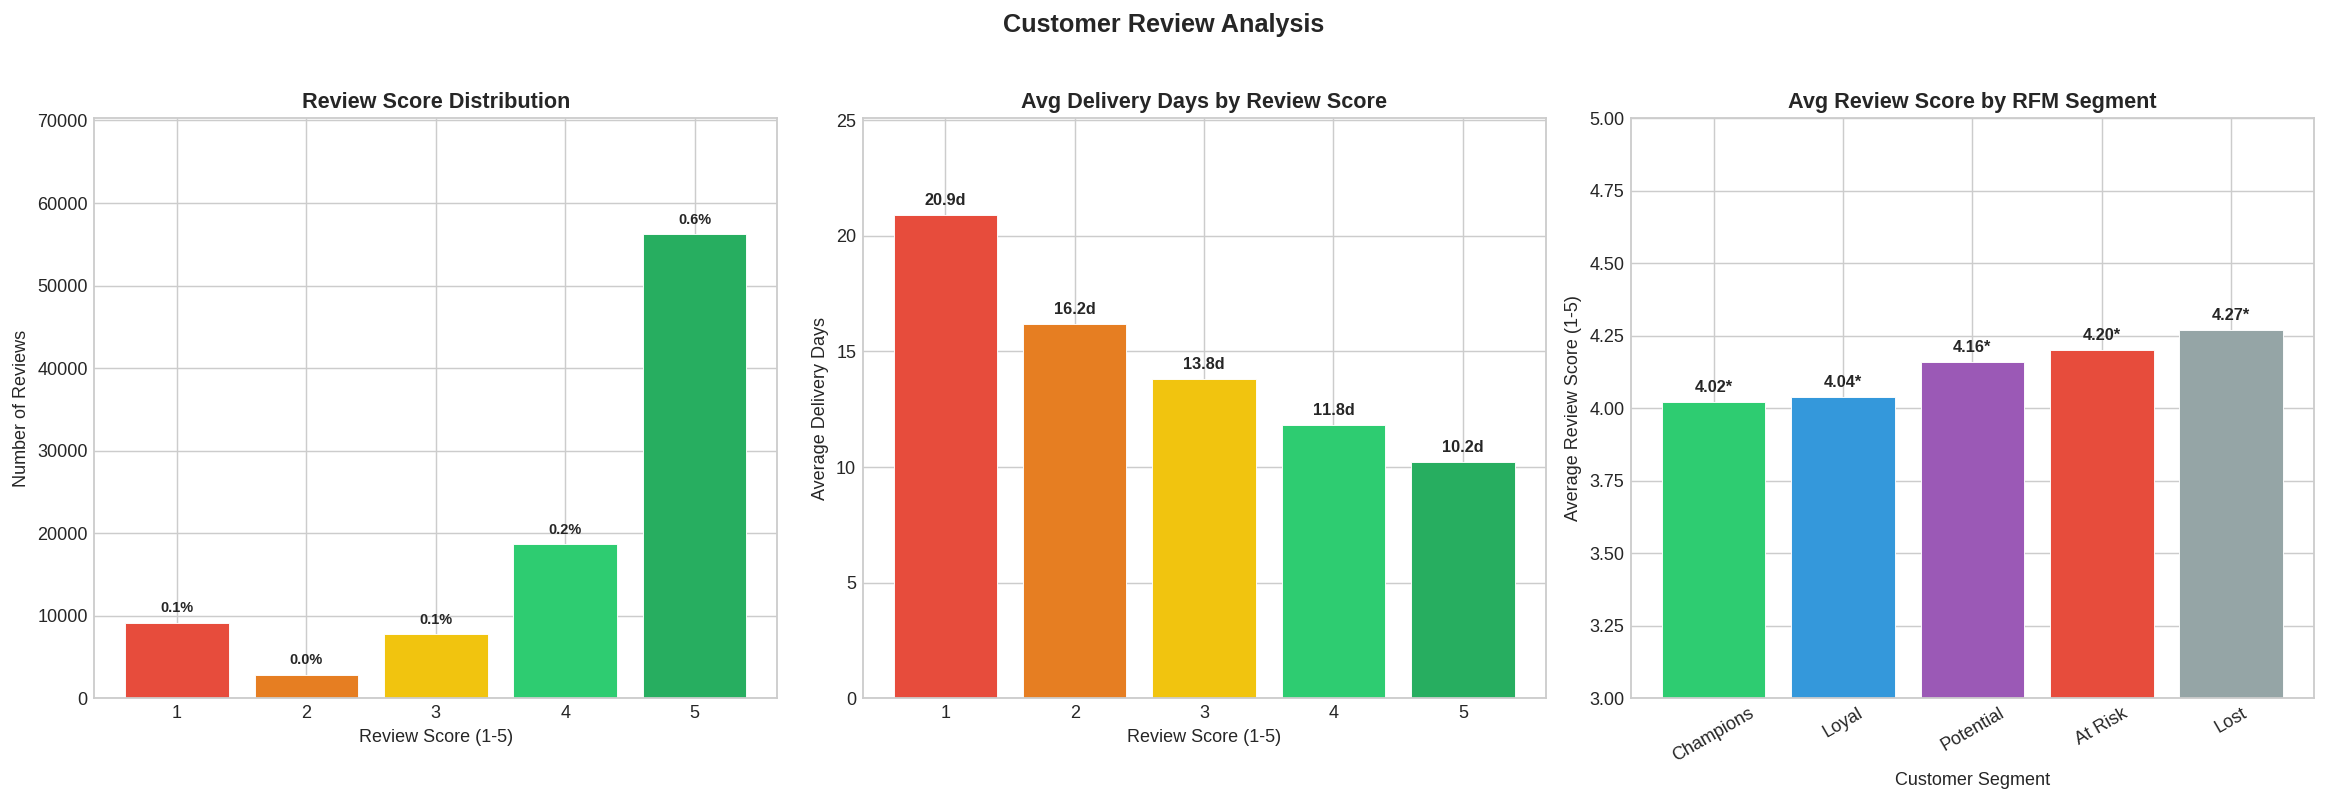

In [ ]:
# Charts
fig, axes = plt.subplots(1, 3, figsize=(18,6))

# Chart 1 - Score Distribution
score_counts = (master_orders_full['review_score']
                .dropna()
                .value_counts()
                .sort_index())

score_colors = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']

bars = axes[0].bar(score_counts.index, score_counts.values, color = score_colors, edgecolor = 'white', linewidth = 0.5)

# Add percentage labels
total_reviews = score_counts.sum()
axes[0].bar_label(bars,
                  labels = [f"{v/total_reviews:.1f}%" for v in score_counts.values],
                  padding = 4, fontsize = 8, fontweight = 'bold')
axes[0].set_title("Review Score Distribution", fontweight = 'bold')
axes[0].set_xlabel("Review Score (1-5)")
axes[0].set_ylabel("Number of Reviews")
axes[0].set_ylim(0, score_counts.max() * 1.25)

# Chart 2 - Average Delivery Days by Review Score
delivery_by_score = (master_orders_full
                     .groupby('review_score')['delivery_days']
                     .mean()
                     .round(1))

bars2 = axes[1].bar(delivery_by_score.index, delivery_by_score.values, color = score_colors, edgecolor = 'white', linewidth = 0.5)
axes[1].bar_label(bars2,
    labels=[f"{v:.1f}d" for v in delivery_by_score.values],
    padding=4, fontsize=9, fontweight='bold')

axes[1].set_title('Avg Delivery Days by Review Score',
                   fontweight='bold')
axes[1].set_xlabel('Review Score (1-5)')
axes[1].set_ylabel('Average Delivery Days')
axes[1].set_ylim(0, delivery_by_score.max() * 1.2)

# Chart 3 - Avg review score by RFM segment
seg_order = ['Champions','Loyal','Potential','At Risk','Lost']
colors_map = {
    'Champions': '#2ecc71',
    'Loyal':     '#3498db',
    'Potential': '#9b59b6',
    'At Risk':   '#e74c3c',
    'Lost':      '#95a5a6'
}

seg_scores = (master_orders_rfm.
              groupby('segment')['review_score']
              .mean()
              .reindex(seg_order)
              .round(2))

bars3 = axes[2].bar(seg_scores.index,
                    seg_scores.values,
                    color = [colors_map[s] for s in seg_order],
                    edgecolor = 'white', linewidth = 0.5)
axes[2].bar_label(bars3,
                  labels = [f"{v:.2f}*" for v in seg_scores.values],
                  padding=4, fontsize=9, fontweight='bold')
axes[2].set_title('Avg Review Score by RFM Segment',
                   fontweight='bold')
axes[2].set_xlabel('Customer Segment')
axes[2].set_ylabel('Average Review Score (1-5)')
axes[2].set_ylim(3, 5)
axes[2].tick_params(axis='x', rotation=30)

plt.suptitle('Customer Review Analysis',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
# plt.savefig('../charts/review_analysis.png', dpi=150,bbox_inches='tight')
plt.show()

The supporting numbers, including the Pearson correlation between delivery days and review
score.

In [ ]:
# Print supporting stats
print("Score Distribution:")
print(score_counts)
print(f"\nOverall avg score: {master_orders_full['review_score'].mean():.2f}")
print(f"% 5-star reviews: {score_counts[5]/total_reviews*100:.1f}%")
print(f"% 1-star reviews: {score_counts[1]/total_reviews*100:.1f}%")
print(f"\nDelivery days by score:")
print(delivery_by_score)
print(f"\nCorrelation (delivery_days vs review_score):")
corr = master_orders_full[['delivery_days','review_score']].corr()
print(f"Pearson r = {corr.loc['delivery_days','review_score']:.3f}")
print(f"\nAvg score by segment:")
print(seg_scores)

Score Distribution:
review_score
1.0     9167
2.0     2873
3.0     7803
4.0    18721
5.0    56209
Name: count, dtype: int64

Overall avg score: 4.16
% 5-star reviews: 59.3%
% 1-star reviews: 9.7%

Delivery days by score:
review_score
1.0    20.9
2.0    16.2
3.0    13.8
4.0    11.8
5.0    10.2
Name: delivery_days, dtype: float64

Correlation (delivery_days vs review_score):
Pearson r = -0.335

Avg score by segment:
segment
Champions    4.02
Loyal        4.04
Potential    4.16
At Risk      4.20
Lost         4.27
Name: review_score, dtype: float64


## Finding — Customer Review Analysis

### Overall satisfaction is strong but polarised
Olist maintains an overall average score of 4.16★ across 94,773
reviews, with 59.3% of customers leaving 5-star ratings. However
the distribution is J-shaped — 1-star reviews (9.7%, 9,167
reviews) form the second largest group, with 2-star and 3-star
reviews being significantly less common. This polarisation is
typical of e-commerce marketplaces: delighted customers and
frustrated customers both review actively, while the
underwhelmed middle often stays silent.

### Delivery time is the single strongest driver of satisfaction
The relationship between delivery speed and review score is
perfectly monotonic — every star improvement corresponds to
faster delivery without exception:

* 1★ → 20.9 days average delivery
* 2★ → 16.2 days
* 3★ → 13.8 days
* 4★ → 11.8 days
* 5★ → 10.2 days

The gap between a 1-star and 5-star delivery experience is
10.7 days - customers who left the worst reviews waited more
than twice as long as those who left the best reviews. The
Pearson correlation of -0.335 between delivery days and review
score confirms this relationship is statistically meaningful:
for every additional day of delivery time, the expected review
score decreases by approximately 0.03 stars on average.

This finding directly connects to the geographic analysis —
BA customers face a median 16-day delivery vs SP's 7 days,
and this delivery gap almost certainly contributes to regional
satisfaction differences. Improving logistics in slow-delivery
states isn't just an operational improvement — it's a direct
lever on customer satisfaction scores.

### The counterintuitive segment pattern
Review scores show an unexpected reverse ranking across RFM
segments:

* Lost:       4.27★ ← highest
* At Risk:    4.20★
* Potential:  4.16★
* Loyal:      4.04★
* Champions:  4.02★ ← lowest

Champions and Loyal customers leave the lowest average scores
despite being the most valuable. This reflects elevated
expectations from experienced buyers — a customer who has
ordered 5 times has encountered the full range of Olist's
service quality and rates more critically than a first-time
buyer. Lost customers' higher scores likely reflect reviews
left during an initial positive experience before whatever
drove them away happened — or a single good delivery before
they disengaged from the platform entirely.

This insight matters for interpretation: a falling average
review score could paradoxically be a sign of improving
customer quality — more experienced, loyal buyers rating
more critically — rather than declining service quality.
Context always matters when reading aggregate satisfaction
metrics.

Business recommendation: three clear actions emerge:

- Delivery speed is the highest-leverage satisfaction lever
  in the entire dataset. Reducing average delivery time by
  even 2 days across all orders would likely improve average
  review scores by ~0.06 stars and reduce the 1-star rate
  meaningfully. Given that 1-star reviews are publicly
  visible and deter new buyers, this has both satisfaction
  and acquisition implications

- The 10.7-day delivery gap between 1-star and 5-star
  experiences suggests a threshold effect around 12-13 days
  — orders arriving within this window tend to score 4★ or
  above, while those exceeding it trend toward 1-2★. Setting
  a 12-day delivery SLA as an internal operational target
  and flagging orders at risk of missing it for priority
  handling could meaningfully shift the score distribution

- Champions' lower average scores (4.02★) relative to Lost
  customers (4.27★) should not trigger alarm — it reflects
  healthy, experienced buyer behaviour. Monitor Champions'
  score trend over time rather than the absolute level:
  if Champions' scores are declining quarter-over-quarter,
  that is a genuine service quality signal worth acting on

---

# 📊 Key Findings Summary — Olist E-Commerce Analysis

## Dataset
- **Source:** Olist Brazilian E-Commerce Public Dataset (Kaggle)
- **Scope:** 96,461 delivered orders · 81,005 unique customers ·
  18-month stable period (Jan 2017 – Jul 2018)
- **Tools:** Python · Pandas · Matplotlib · Seaborn · SQL (DuckDB)

---

## 1. Revenue
- Revenue grew consistently from R\$127k (Jan 2017) to R\$1.03M
  (Jul 2018), peaking at **R\$1.15M in November 2017** — a 53.5%
  MoM spike driven by Black Friday
- The 3-month rolling average confirms underlying upward trend
  throughout the period despite month-to-month volatility
- **December 2017 saw a 27% post-holiday correction** — typical
  seasonal pattern for marketplace businesses

## 2. Time Patterns
- Orders are concentrated in an unusually broad **10-hour active
  window (11am–9pm)** — no single lunch-hour spike as seen in
  typical e-commerce platforms
- **16:00 is the peak hour** with 6,475 orders but 10 other hours
  are within 10% of that figure — scheduling flexibility for
  campaigns is high
- Midnight (hour 0) shows a disproportionate 2,321 orders — likely
  a UTC timezone offset artifact rather than genuine midnight
  purchasing behaviour

## 3. Products
- **health_beauty** leads total revenue (R\$1.1M) with highest order
  penetration (8.73% of all orders)
- **watches_gifts** is the premium outlier — #2 by revenue but only
  5.68% penetration with avg order value of R\$214 (94% higher than
  bed_bath_table at R\$110)
- Items per order is uniformly 1.04–1.24 across all categories —
  virtually no in-category bundling behaviour, representing an
  untapped cross-sell opportunity

## 4. Customers
- **97% of customers (78,591) placed only one order** — Olist
  operates with an extremely high one-time buyer rate typical of
  marketplace models
- Repeat customers (3%, 2,414) generate R$307 average LTV —
  significantly higher per-customer value than one-time buyers
- New customer acquisition grew **718% from Jan 2017 to Jun 2018**,
  decelerating to a steady state of ~6,000–6,500/month from early 2018

## 5. Cohort Retention
- Month-1 retention ranges from **0.18% to 0.72%** — sub-1% across
  all cohorts, consistent with the 97% one-time buyer rate
- Retention improved consistently through 2017 (0.28% → 0.72%),
  suggesting platform maturity drives stickiness
- **Black Friday cohort (Nov 2017) underperformed** surrounding
  months at 0.57% Month-1 retention — promotional acquisition
  brings volume but not loyalty

## 6. Geography
- **SP alone drives ~40% of total revenue** — 3x the next largest
  state (RJ). Just 7 states account for 80% of all revenue
  (classic Pareto concentration)
- **Northern states show highest AOV** (PB: R\$260, AC: R\$250)
  despite lowest order volumes — high-spending customers in
  underserved markets
- Delivery gap between fastest (SP: 7 days) and slowest (AM/RR:
  25 days) states is **18 days — 3.6x longer** — a direct
  customer experience divide mapping to Brazil's infrastructure
  reality

## 7. RFM Segmentation
- **At Risk customers drive 34.7% of revenue** (R\$4.6M) — more
  than Champions (30.3%, R\$4.0M) — reflecting their historical
  high-value purchases before churning
- Champions and At Risk together are **40% of customers but 65%
  of revenue** — the highest-priority retention targets
- **Potential segment (23.5% of customers) generates only 7.8%
  of revenue** — the largest gap between customer share and
  revenue share — representing the biggest growth opportunity
  without new acquisition

## 8. Reviews
- Overall avg score: **4.16★** with 59.3% five-star reviews and
  9.7% one-star reviews — a J-shaped distribution typical of
  marketplace platforms
- Delivery time is the **single strongest satisfaction driver**
  (Pearson r = -0.335): 1-star customers waited avg 20.9 days
  vs 10.2 days for 5-star customers — a 10.7-day gap
- **Champions leave the lowest scores (4.02★)** and Lost customers
  the highest (4.27★) — reflecting experienced buyer expectations,
  not service quality decline

---

## Strategic Priority Matrix

| Priority | Segment/Area | Action | Est. Revenue Impact |
|----------|-------------|--------|-------------------|
| 🔴 Urgent | At Risk customers | Win-back campaign | R\$230k+ |
| 🔴 Urgent | Delivery speed | Reduce avg by 2 days | Score +0.06★ |
| 🟡 High | Potential customers | Category cross-sell | R\$2,343,396 incremental |
| 🟡 High | Northern states | Logistics partnership | High AOV market |
| 🟢 Medium | Champions | Loyalty programme | Protect R\$4M revenue |
| 🟢 Medium | Black Friday | Cap promotional spend | Better cohort quality |

---

*Analysis conducted by Dev Gupta · Dataset: Olist Brazilian
E-Commerce (Kaggle) · Tools: Python, Pandas, Matplotlib, Seaborn*